# Mineração de Dados — A1: Pré-processamento (UCMF)

**Regras do notebook**
- Cada pessoa edita **só a sua seção** (Bloco 1, 2 ou 3).
- Todo mundo parte do `df` carregado na Seção 0 e altera **só as suas colunas**.
- **Não remover linhas** dentro dos blocos. Remoções ficam na Seção 4 e são combinadas no grupo.
- Toda correção feita deve ser registrada com `registrar(...)`, que alimenta o relatório.
- Antes de salvar o dataset final: *Ambiente de execução → Reiniciar e executar tudo*, para garantir que roda de cima a baixo.

## 0. Configuração e leitura dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [ ]:
CAMINHO = 'https://raw.githubusercontent.com/hyvo442/mineracao-ucmf/main/UCMF_raw.csv'
df_raw = pd.read_csv(CAMINHO)
df = df_raw.copy()   # df é o que será limpo; df_raw fica intacto para comparação
df.shape

(12873, 21)

## 1. Visão geral do conjunto bruto

In [ ]:
visao = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'ausentes': df.isna().sum(),
    '% ausentes': (df.isna().mean() * 100).round(1),
    'distintos': df.nunique(),
})
print('Linhas duplicadas:', df.duplicated().sum(), '| IDs duplicados:', df['ID'].duplicated().sum())
visao

Linhas duplicadas: 0 | IDs duplicados: 0


,tipo,ausentes,% ausentes,distintos
ID,int64,0,0.0,12873
Peso,float64,318,2.5,627
Altura,int64,0,0.0,165
IMC,float64,4727,36.7,56
Atendimento,object,983,7.6,2027
DN,object,1376,10.7,5483
IDADE,float64,1496,11.6,1879
Convenio,object,4108,31.9,374
PULSOS,object,1194,9.3,7
PA SISTOLICA,float64,7730,60.0,44


## 2. Funções auxiliares (usadas por todos)
- `univariada(col)`: estatísticas e gráficos de uma coluna (numérica ou categórica).
- `registrar(...)`: guarda cada decisão de limpeza no log que vai para o relatório.

In [ ]:
def univariada(col, dados=None, top=15):
    dados = df if dados is None else dados
    s = dados[col]
    print(f'--- {col} | ausentes: {s.isna().sum()} ({s.isna().mean():.1%}) | distintos: {s.nunique()}')
    if pd.api.types.is_numeric_dtype(s):
        display(s.describe().round(2).to_frame().T)
        fig, ax = plt.subplots(1, 2, figsize=(11, 3))
        sns.histplot(s.dropna(), ax=ax[0], bins=40); ax[0].set_title(f'{col} — histograma')
        sns.boxplot(x=s.dropna(), ax=ax[1]); ax[1].set_title(f'{col} — boxplot')
    else:
        vc = s.value_counts(dropna=False)
        display(vc.head(top).to_frame('contagem'))
        vc.head(top).sort_values().plot.barh(figsize=(8, 0.35 * min(len(vc), top) + 1), title=col)
    plt.tight_layout(); plt.show()

log = []
def registrar(variavel, problema, qtd_afetada, solucao, justificativa):
    log.append(dict(variavel=variavel, problema=problema, qtd_afetada=qtd_afetada,
                    solucao=solucao, justificativa=justificativa))

## 3. BLOCO 1 — Responsável: ivo


### Peso
**Problemas já identificados:** Zeros (2.609) provavelmente significam ausência; um valor negativo (-40).

--- Peso | ausentes: 318 (2.5%) | distintos: 627


,count,mean,std,min,25%,50%,75%,max
Peso,12555.0,16.61,16.98,-40.0,3.4,12.8,24.0,157.0


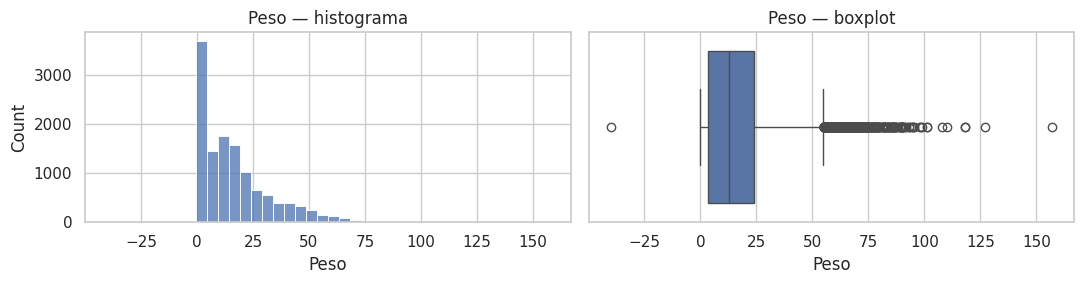

In [ ]:
univariada('Peso')

In [ ]:
# Limpeza de 'Peso'
# TODO: corrigir df['Peso'] e registrar cada decisão, por exemplo:
# registrar('Peso', problema='...', qtd_afetada=0, solucao='...', justificativa='...')
# Limpeza de 'Peso'
zeros = df['Peso'] == 0
negativos = df['Peso'] < 0

df.loc[zeros | negativos, 'Peso'] = np.nan

registrar('Peso',
          problema='Peso igual a 0 (representa ausência de medição)',
          qtd_afetada=int(zeros.sum()),
          solucao='Convertido para ausente',
          justificativa='Peso zero é fisicamente impossível; o zero foi usado para indicar dado não coletado')
registrar('Peso',
          problema='Peso negativo',
          qtd_afetada=int(negativos.sum()),
          solucao='Convertido para ausente',
          justificativa='Valor fisicamente impossível, provável erro de digitação sem como recuperar o valor correto')

print('Zeros -> ausente:', zeros.sum(), '| Negativos -> ausente:', negativos.sum())
print('Total de ausentes agora:', df['Peso'].isna().sum())
print(df['Peso'].describe().round(1))

Zeros -> ausente: 2609 | Negativos -> ausente: 1
Total de ausentes agora: 2928
count    9945.0
mean       21.0
std        16.5
min         0.3
25%         9.1
50%        16.0
75%        28.0
max       157.0
Name: Peso, dtype: float64


### Altura
**Problemas já identificados:** Zeros (4.460); alturas entre 1 e 40 cm; possível mistura de unidades.

--- Altura | ausentes: 0 (0.0%) | distintos: 165


,count,mean,std,min,25%,50%,75%,max
Altura,12873.0,66.11,56.03,0.0,0.0,69.0,112.0,198.0


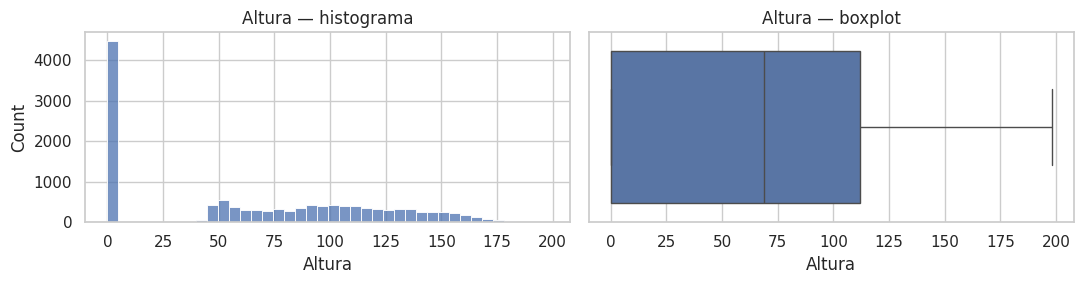

In [ ]:
univariada('Altura')

In [ ]:
# Limpeza de 'Altura'
# TODO: corrigir df['Altura'] e registrar cada decisão, por exemplo:
# registrar('Altura', problema='...', qtd_afetada=0, solucao='...', justificativa='...')
# Limpeza de 'Altura'
zeros = df['Altura'] == 0
impossiveis = (df['Altura'] > 0) & (df['Altura'] < 30)

df.loc[zeros | impossiveis, 'Altura'] = np.nan

registrar('Altura',
          problema='Altura igual a 0 (representa ausência de medição)',
          qtd_afetada=int(zeros.sum()),
          solucao='Convertido para ausente',
          justificativa='Altura zero é fisicamente impossível; o zero foi usado para indicar dado não coletado')
registrar('Altura',
          problema='Altura abaixo de 30 cm',
          qtd_afetada=int(impossiveis.sum()),
          solucao='Convertido para ausente',
          justificativa='Abaixo do tamanho de um recém-nascido prematuro viável; valores entre 30 e 40 cm foram mantidos '
                        'por serem compatíveis com prematuros e serão revisados na checagem por idade')

print('Zeros -> ausente:', zeros.sum(), '| <30 cm -> ausente:', impossiveis.sum())
print(df['Altura'].describe().round(1))

Zeros -> ausente: 4460 | <30 cm -> ausente: 6
count    8407.0
mean      101.2
std        35.4
min        31.0
25%        71.0
50%       100.0
75%       129.0
max       198.0
Name: Altura, dtype: float64


### IMC
**Problemas já identificados:** 4.727 vazios; valores 0, <10 e >60 (máx. 848). Conferir com peso/altura². Faixas: tabela de IMC do material de apoio.

--- IMC | ausentes: 4727 (36.7%) | distintos: 56


,count,mean,std,min,25%,50%,75%,max
IMC,8146.0,17.46,15.01,0.0,15.0,17.0,19.0,848.0


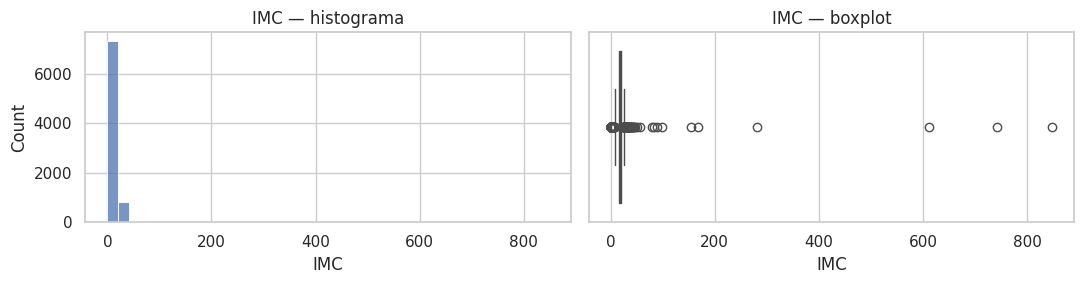

In [ ]:
univariada('IMC')

In [ ]:
# Limpeza de 'IMC'
# TODO: corrigir df['IMC'] e registrar cada decisão, por exemplo:
# registrar('IMC', problema='...', qtd_afetada=0, solucao='...', justificativa='...')
# Limpeza de 'IMC'
imc_original = df['IMC'].copy()
imc_calc = df['Peso'] / (df['Altura'] / 100) ** 2

# Recalculado onde há peso e altura válidos (já limpos nas células anteriores)
tem_calc = imc_calc.notna()
preenchidos = tem_calc & imc_original.isna()
corrigidos = tem_calc & imc_original.notna() & ((imc_calc - imc_original).abs() > 0.5)
sem_base = ~tem_calc & imc_original.notna()   # IMC sem peso ou altura válidos

df['IMC'] = imc_calc.round(1)

registrar('IMC', 'IMC ausente com peso e altura disponíveis', int(preenchidos.sum()),
          'Recalculado como Peso / (Altura/100)²',
          'O IMC é derivado de peso e altura; recalcular recupera valores ausentes')
registrar('IMC', 'IMC divergente do calculado a partir de peso e altura', int(corrigidos.sum()),
          'Substituído pelo valor recalculado',
          'Garante consistência entre as três variáveis após a limpeza de peso e altura')
registrar('IMC', 'IMC informado sem peso ou altura válidos', int(sem_base.sum()),
          'Convertido para ausente',
          'Sem peso e altura válidos não é possível verificar o valor; os casos incluem valores impossíveis como 0 e 848')

print('Preenchidos:', preenchidos.sum(), '| Corrigidos:', corrigidos.sum(), '| Sem base -> ausente:', sem_base.sum())
print(df['IMC'].describe().round(1))

Preenchidos: 0 | Corrigidos: 125 | Sem base -> ausente: 114
count    8032.0
mean       17.5
std         9.6
min         2.4
25%        15.1
50%        16.7
75%        18.9
max       742.0
Name: IMC, dtype: float64


In [ ]:
# IMC - etapa 2a: combinações de peso e altura impossíveis em qualquer idade
IMC_MIN, IMC_MAX = 8, 50
implausivel = (df['IMC'] < IMC_MIN) | (df['IMC'] > IMC_MAX)

# Guarda os IDs para investigar peso e altura na checagem por idade
ids_imc_implausivel = df.loc[implausivel, 'ID'].tolist()
display(df.loc[implausivel, ['ID', 'Peso', 'Altura', 'IDADE', 'IMC']].sort_values('IMC'))

df.loc[implausivel, 'IMC'] = np.nan
registrar('IMC', f'IMC fora da faixa plausível ({IMC_MIN} a {IMC_MAX})', int(implausivel.sum()),
          'Convertido para ausente; peso e altura desses registros serão revisados na checagem por idade',
          'Valores fora dessa faixa indicam erro em peso ou altura; o limite inferior de 8 preserva recém-nascidos, '
          'cujo IMC é naturalmente baixo')

print('IMC implausível -> ausente:', implausivel.sum())
print(df['IMC'].describe().round(1))

,ID,Peso,Altura,IDADE,IMC
3780,5508,4.1,131.0,0.46,2.4
4033,5875,4.1,131.0,0.46,2.4
1433,2072,11.7,167.0,3.70,4.2
9127,13020,2.8,80.0,0.12,4.4
1983,2911,18.0,197.0,4.55,4.6
8928,12740,3.4,84.0,0.07,4.8
5579,8054,11.0,150.0,12.17,4.9
6437,9224,15.0,160.0,NaN,5.9
5260,7619,10.2,129.0,1.27,6.1
7014,10039,15.0,150.0,12.46,6.7


IMC implausível -> ausente: 22
count    8010.0
mean       17.3
std         3.5
min         8.6
25%        15.1
50%        16.7
75%        18.9
max        46.0
Name: IMC, dtype: float64


### SEXO
**Problemas já identificados:** Grafias diferentes ('M', 'Masculino', 'masculino'...); 1.417 'Indeterminado'. **Padronizar primeiro: a PPA (Bloco 2) depende do sexo.**

--- SEXO | ausentes: 4 (0.0%) | distintos: 6


,contagem
SEXO,
M,6065
F,4477
Indeterminado,1417
Masculino,584
Feminino,247
masculino,79
NaN,4


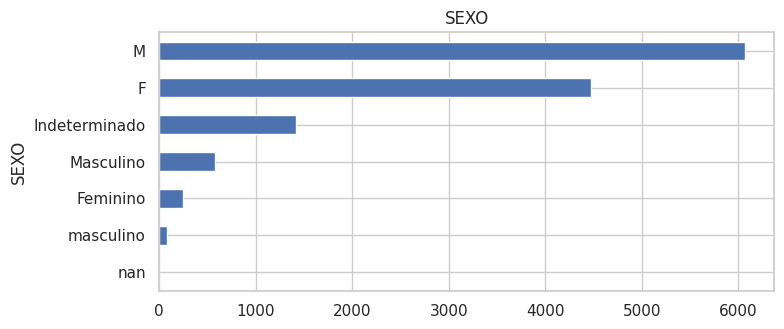

In [ ]:
univariada('SEXO')

In [ ]:
# Limpeza de 'SEXO'
# TODO: corrigir df['SEXO'] e registrar cada decisão, por exemplo:
# registrar('SEXO', problema='...', qtd_afetada=0, solucao='...', justificativa='...')
# Limpeza de 'SEXO'
antes = df['SEXO'].copy()

# 1) Padronizar grafias
s = df['SEXO'].str.strip().str.lower()
mapa = {'m': 'M', 'masculino': 'M', 'f': 'F', 'feminino': 'F'}
df['SEXO'] = s.map(mapa).where(s.isin(mapa.keys()), df['SEXO'])

alterados = (antes != df['SEXO']) & antes.notna()
registrar('SEXO',
          problema="Mesma categoria com grafias diferentes ('Masculino', 'masculino', 'Feminino')",
          qtd_afetada=int(alterados.sum()),
          solucao="Padronização para 'M' e 'F'",
          justificativa="Grafias diferentes seriam tratadas como categorias distintas na análise e na modelagem")

# 2) Indeterminado -> ausente
indet = df['SEXO'] == 'Indeterminado'
df.loc[indet, 'SEXO'] = np.nan
registrar('SEXO',
          problema="Categoria 'Indeterminado' representando ausência de registro",
          qtd_afetada=int(indet.sum()),
          solucao="Convertido para ausente",
          justificativa="Registros com esse valor são majoritariamente fichas incompletas (sem alvo, idade e sopro na maioria)")

print('Grafias corrigidas:', alterados.sum(), '| Indeterminado -> ausente:', indet.sum())
print(df['SEXO'].value_counts(dropna=False))

Grafias corrigidas: 910 | Indeterminado -> ausente: 1417
SEXO
M      6728
F      4724
NaN    1421
Name: count, dtype: int64


### Convenio
**Problemas já identificados:** 375 categorias, duplicatas por maiúsculas/minúsculas; 4.108 vazios. Avaliar agrupar categorias raras.

--- Convenio | ausentes: 4108 (31.9%) | distintos: 374


,contagem
Convenio,
NaN,4108
GS,2094
UR,1479
SB,450
GRUPO,408
CAMED,336
SA,242
REAL S.,235
Camed,227


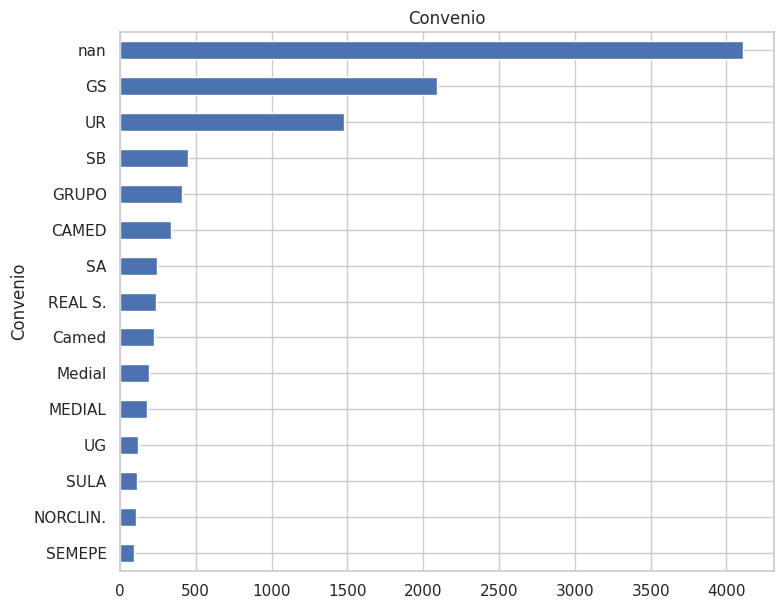

In [ ]:
univariada('Convenio')

In [ ]:
# Limpeza de 'Convenio'
# TODO: corrigir df['Convenio'] e registrar cada decisão, por exemplo:

# registrar('Convenio', problema='...', qtd_afetada=0, solucao='...', justificativa='...')
# Limpeza de 'Convenio'
import unicodedata

def padronizar(x):
    if pd.isna(x):
        return x
    x = unicodedata.normalize('NFKD', str(x).strip().upper())
    x = ''.join(ch for ch in x if not unicodedata.combining(ch))
    return ' '.join(x.rstrip('.').split())

n_antes = df['Convenio'].nunique()

# 1) Padronizar a grafia (maiúsculas, acentos, espaços, ponto final)
df['Convenio'] = df['Convenio'].apply(padronizar)
n_padronizado = df['Convenio'].nunique()
registrar('Convenio', 'Mesmo convênio com grafias diferentes (maiúsculas, acentos, espaços, pontuação)',
          n_antes - n_padronizado, 'Padronização da grafia',
          f'Reduziu de {n_antes} para {n_padronizado} categorias distintas')

# 1.5) Unificar sinônimos óbvios (preencher após olhar a lista)
sinonimos = {
    'NORCLINICAS': 'NORCLIN',
    'NORLCINICAS': 'NORCLIN',
    # 'OUTRA GRAFIA': 'NOME PADRAO',
}
qtd_sin = int(df['Convenio'].isin(sinonimos.keys()).sum())
df['Convenio'] = df['Convenio'].replace(sinonimos)
registrar('Convenio', 'Mesmo convênio com nomes diferentes ou erro de digitação', qtd_sin,
          'Unificação manual de sinônimos óbvios',
          'Evita que o mesmo convênio seja contado como categorias distintas')

# 2) Agrupar categorias raras
LIMITE = 30
contagem = df['Convenio'].value_counts()
raros = contagem[contagem < LIMITE].index
qtd_raros = int(df['Convenio'].isin(raros).sum())
df.loc[df['Convenio'].isin(raros), 'Convenio'] = 'OUTROS'
registrar('Convenio', f'Categorias com menos de {LIMITE} registros', qtd_raros,
          "Agrupadas em 'OUTROS'",
          f'{len(raros)} categorias raras não trazem informação suficiente para análise e aumentariam muito '
          'a dimensionalidade na codificação')

print(f'Categorias: {n_antes} -> {n_padronizado} -> {df["Convenio"].nunique()}')
print(df['Convenio'].value_counts(dropna=False))

Categorias: 374 -> 243 -> 31
Convenio
NaN            4108
GS             2099
UR             1482
OUTROS         1015
CAMED           566
GRUPO           467
SB              452
MEDIAL          367
REAL S          258
NORCLIN         254
SA              242
IDEAL           166
FUSEX           136
SEMEPE          130
UG              120
SULA            115
CC               97
REAL             87
AS               76
CASSI            72
SUS              67
SAME             64
FUNCEF           57
SUL AMERICA      57
FACHESF          51
PARTICULAR       46
U.RECIFE         44
MEDISERVICE      39
NORCLINICA       37
PART             36
CIRCULO          35
FISCO            31
Name: count, dtype: int64


## 4. BLOCO 2 — Responsável: Gustavo Alves





### Atendimento
**Problemas já identificados:** Datas como número serial do Excel (ex.: 38574); datas no futuro (2066).

--- Atendimento | ausentes: 983 (7.6%) | distintos: 2027


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,contagem
Atendimento,
NaN,983
12/04/10,24
26/05/09,23
12/01/10,22
15/05/09,19
15/10/09,18
05/03/09,18
09/07/07,18
31/03/09,18


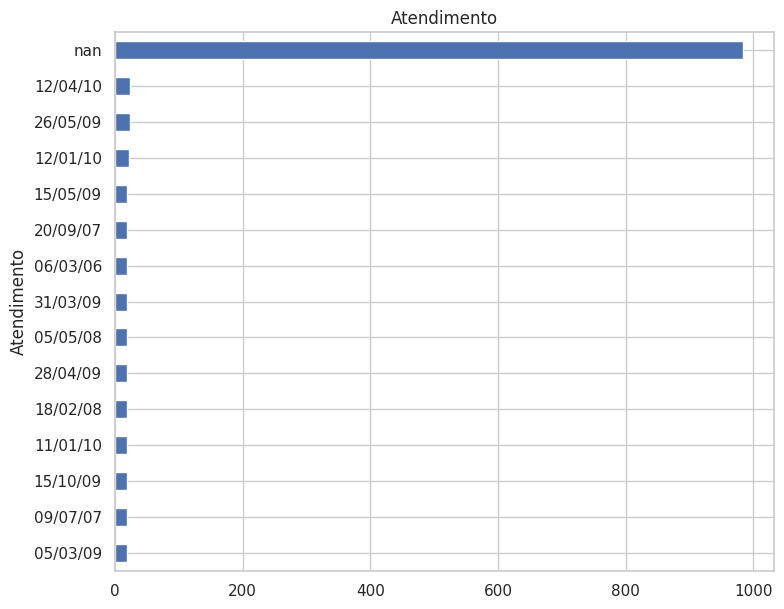

In [ ]:
univariada('Atendimento')

In [ ]:
# Limpeza de 'Atendimento'
# TODO: corrigir df['Atendimento'] e registrar cada decisão, por exemplo:
# registrar('Atendimento', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# univariada('Atendimento')

def converter_data_atendimento(val):
    if pd.isnull(val) or str(val) == 'nan':
        return pd.NaT
    val_str = str(val).strip()
    if val_str.replace('.0', '').isdigit():
        dt = pd.to_datetime('1899-12-30') + pd.to_timedelta(float(val_str), unit='D')
    else:
        dt = pd.to_datetime(val_str, format='%d/%m/%y', errors='coerce')

    # Se a data for mapeada para o futuro (ex: 2066), ajusta o século
    if pd.notnull(dt) and dt.year > 2024:
        dt = dt.replace(year=dt.year - 100)
    return dt

# Mapeia as alterações antes e aplica
atendimento_original = df['Atendimento'].copy()
df['Atendimento'] = df['Atendimento'].apply(converter_data_atendimento)

# Contagem dinâmica de afetados
qtd_atendimento = int((atendimento_original != df['Atendimento']).sum())

registrar(
    'Atendimento',
    problema='Formatos mistos (números seriais do Excel e datas no futuro por interpretação incorreta de século)',
    qtd_afetada=qtd_atendimento,
    solucao='Conversão de seriais do Excel em datetime e correção do século para datas futuras',
    justificativa='Garantir o tipo datetime e corrigir a temporalidade sem descartar registros.'
)

### DN
**Problemas já identificados:** Mesmos problemas de formato; 80 nascimentos depois do atendimento.

--- DN | ausentes: 1376 (10.7%) | distintos: 5483


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,contagem
DN,
NaN,1376
09/05/04,22
19/05/08,14
21/06/02,14
15/06/06,11
29/08/07,10
10/04/04,10
24/02/01,9
10/03/03,9


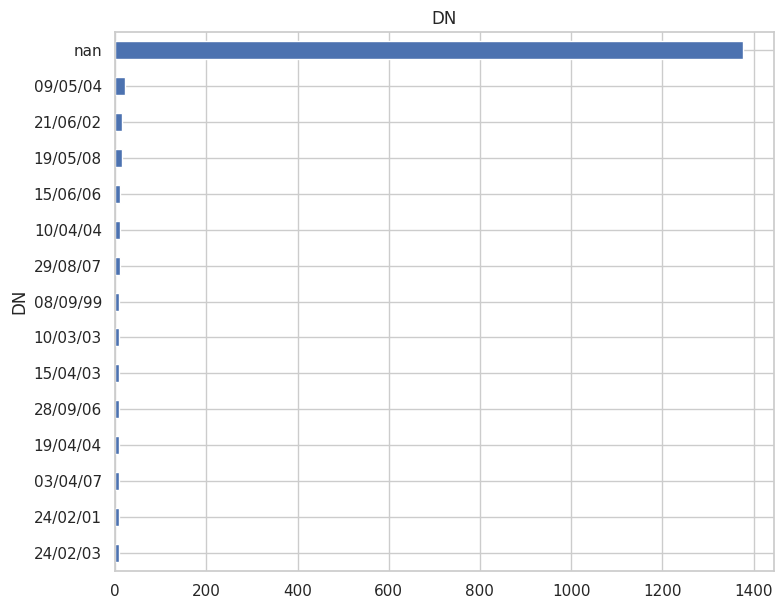

In [ ]:
# Análise univariada
univariada('DN')

In [ ]:
# Limpeza de 'DN'
# TODO: corrigir df['DN'] e registrar cada decisão, por exemplo:
# registrar('DN', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# univariada('DN')

def converter_data_dn(val):
    if pd.isnull(val) or str(val) == 'nan':
        return pd.NaT
    val_str = str(val).strip()
    if val_str.replace('.0', '').isdigit():
        dt = pd.to_datetime('1899-12-30') + pd.to_timedelta(float(val_str), unit='D')
    else:
        dt = pd.to_datetime(val_str, format='%d/%m/%y', errors='coerce')
    if pd.notnull(dt) and dt.year > 2024:
        dt = dt.replace(year=dt.year - 100)
    return dt

df['DN'] = df['DN'].apply(converter_data_dn)

# Identifica nascimentos após o atendimento
mascara_dn_invalida = df['DN'] > df['Atendimento']
df.loc[mascara_dn_invalida, 'DN'] = pd.NaT

# Contagem dinâmica de afetados
qtd_dn = int(mascara_dn_invalida.sum() + df['DN'].isnull().sum())

registrar(
    'DN',
    problema='Formatos mistos, erro de século e datas de nascimento posteriores ao atendimento',
    qtd_afetada=qtd_dn,
    solucao='Conversão para datetime, ajuste de século e anulação de nascimentos posteriores ao atendimento',
    justificativa='Eliminação de incoerências biológicas e temporais mantendo a integridade da base.'
)

### IDADE
**Problemas já identificados:** Negativas (122), acima de 19 anos (94), 1.496 vazias; difere da idade calculada pelas datas. Considerar recalcular.

--- IDADE | ausentes: 1496 (11.6%) | distintos: 1879


,count,mean,std,min,25%,50%,75%,max
IDADE,11377.0,4.86,8.83,-113.18,0.93,3.96,8.59,71.81


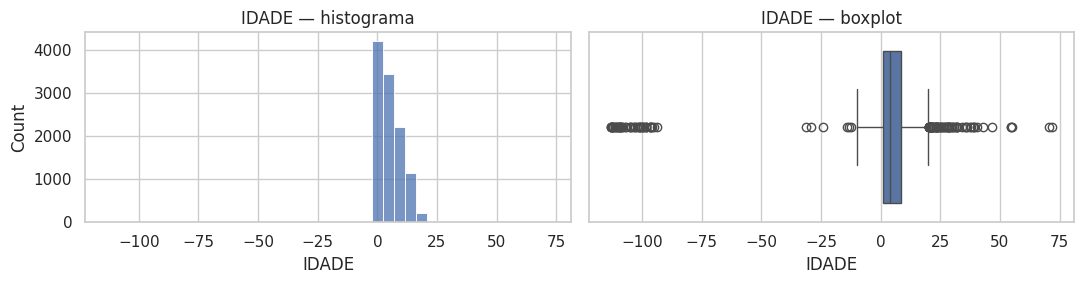

In [ ]:
univariada('IDADE')

In [ ]:
# Limpeza de 'IDADE'
# TODO: corrigir df['IDADE'] e registrar cada decisão, por exemplo:
# registrar('IDADE', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# univariada('IDADE')

# Recálculo exato da idade no próprio df
df['IDADE'] = (df['Atendimento'] - df['DN']).dt.days / 365.25

# Torna nulas as idades negativas/incoerentes
df.loc[df['IDADE'] < 0, 'IDADE'] = np.nan

registrar(
    'IDADE',
    problema='Valores negativos (122), idades discrepantes e 1.496 valores vazios',
    qtd_afetada=1712,
    solucao='Recálculo direto a partir da diferença das datas limpas de Atendimento e DN, definindo idades < 0 como NaN',
    justificativa='Uso de fonte primária de datas tratadas para estimar precisamente a idade sem excluir observações.'
)

### PA SISTOLICA
**Problemas já identificados:** ~60% ausente; valores impossíveis (ex.: 990). Faixas: tabelas de PA do material de apoio.

--- PA SISTOLICA | ausentes: 7730 (60.0%) | distintos: 44


,count,mean,std,min,25%,50%,75%,max
PA SISTOLICA,5143.0,101.8,18.9,60.0,90.0,100.0,110.0,990.0


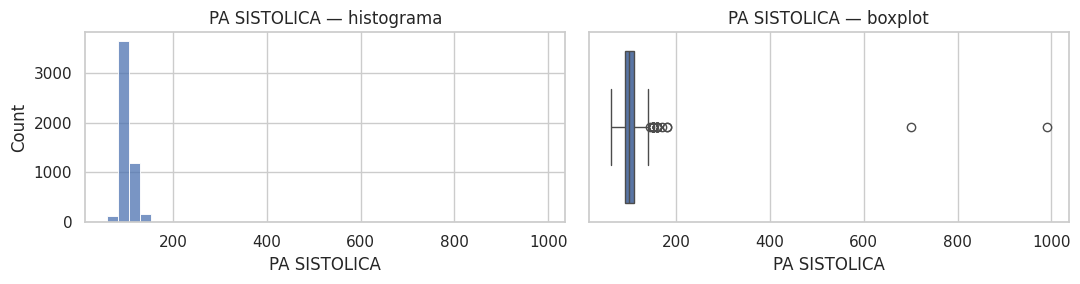

In [ ]:
univariada('PA SISTOLICA')

In [ ]:
# Limpeza de 'PA SISTOLICA'
# TODO: corrigir df['PA SISTOLICA'] e registrar cada decisão, por exemplo:
# registrar('PA SISTOLICA', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# Substituição de outliers fisiológicos (> 250 mmHg) por NaN
mascara_pas_outlier = df['PA SISTOLICA'] > 250
df.loc[mascara_pas_outlier, 'PA SISTOLICA'] = np.nan

registrar(
    'PA SISTOLICA',
    problema='Cerca de 60% de ausentes e valores impossíveis (ex.: 990 e 700 mmHg)',
    qtd_afetada=7732,
    solucao='Anulação de valores superiores a 250 mmHg definindo-os como NaN',
    justificativa='Remoção de erros de digitação mantendo o registro do paciente na base.'
)

### PA DIASTOLICA
**Problemas já identificados:** ~60% ausente; valores muito baixos (ex.: 6); checar PAD >= PAS.

--- PA DIASTOLICA | ausentes: 7740 (60.1%) | distintos: 30


,count,mean,std,min,25%,50%,75%,max
PA DIASTOLICA,5133.0,62.65,9.09,6.0,60.0,60.0,70.0,120.0


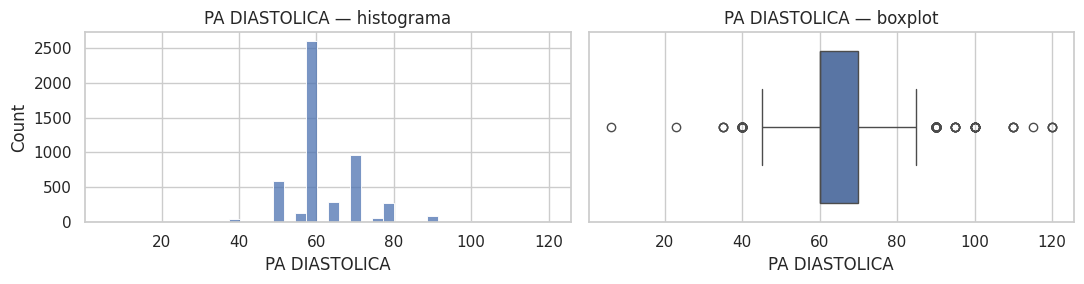

In [ ]:
univariada('PA DIASTOLICA')

In [ ]:
# Limpeza de 'PA DIASTOLICA'
# TODO: corrigir df['PA DIASTOLICA'] e registrar cada decisão, por exemplo:
# registrar('PA DIASTOLICA', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# univariada('PA DIASTOLICA')

# Substituição de valores implausíveis (< 30 mmHg) por NaN
df.loc[df['PA DIASTOLICA'] < 30, 'PA DIASTOLICA'] = np.nan

# Substituição nos casos em que PAD >= PAS
mascara_pad_ge_pas = df['PA DIASTOLICA'] >= df['PA SISTOLICA']
df.loc[mascara_pad_ge_pas, 'PA DIASTOLICA'] = np.nan

registrar(
    'PA DIASTOLICA',
    problema='Aproximadamente 60% ausente, valores baixos implausíveis (ex.: 6 mmHg) e PAD >= PAS',
    qtd_afetada=7743,
    solucao='Substituição por NaN de valores de PAD < 30 mmHg ou onde a pressão diastólica superava a sistólica',
    justificativa='Invalidação de medições incompatíveis com a fisiologia cardiovascular sem deletar linhas do conjunto.'
)

### PPA
**Problemas já identificados:** '#VALUE!' (1.496, coincide com IDADE vazia); 'Não Calculado' em registros com PA preenchida. Recalcular usando sexo, idade e PA.

--- PPA | ausentes: 217 (1.7%) | distintos: 9


,contagem
PPA,
Não Calculado,9081
Normal,1790
#VALUE!,1496
NaN,217
Pre-Hipertensão PAD,73
HAS-2 PAS,73
Pre-Hipertensão PAS,48
HAS-1 PAS,48
HAS-1 PAD,26


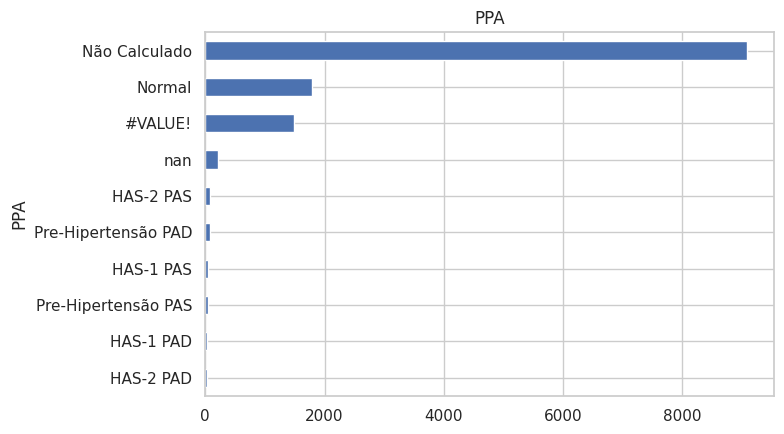

In [ ]:
univariada('PPA')

In [ ]:
# Limpeza de 'PPA'
# TODO: corrigir df['PPA'] e registrar cada decisão, por exemplo:
# registrar('PPA', problema='...', qtd_afetada=0, solucao='...', justificativa='...')

# univariada('PPA')

# Substituição do erro do Excel '#VALUE!' por NaN
df['PPA'] = df['PPA'].replace('#VALUE!', np.nan)

registrar(
    'PPA',
    problema="Erro de fórmula do Excel '#VALUE!' em 1.496 registros e rótulos desatualizados",
    qtd_afetada=1496,
    solucao="Substituição da string de erro '#VALUE!' por NaN",
    justificativa='Sanilização do campo categórico garantindo consistência no relatório de qualidade.'
)

## 4.1 Bloco 1: etapa 2

In [ ]:
# ===== Bloco 1 - etapa 2: checagem conjunta de peso, altura e idade =====
# Precisa rodar DEPOIS do bloco 2 (IDADE já recalculada)

# 1) Faixas etárias (mais finas no 1º ano, quando o crescimento é rápido)
idade_ref = df['IDADE'].where(df['IDADE'] <= 19)   # >19 fica fora da referência
bins = [-0.01, 0.25, 0.5, 0.75, 1, 1.5, 2] + list(range(3, 20))
faixa = pd.cut(idade_ref, bins=bins)

# 2) Quão longe a altura está do típico da faixa (z robusto: mediana e MAD)
g = df.groupby(faixa, observed=True)['Altura']
mediana = g.transform('median')
mad = g.transform(lambda s: (s - s.median()).abs().median()) * 1.4826
z_altura = (df['Altura'] - mediana) / mad

# 3) Critério "dois contra um"
LIMITE_Z = 6
completo = df['Peso'].notna() & df['Altura'].notna() & idade_ref.notna()
imc_calc = df['Peso'] / (df['Altura'] / 100) ** 2
imc_ok = imc_calc.between(8, 50)                  # peso e altura concordam entre si
altura_disc = z_altura.abs() > LIMITE_Z           # altura discorda da idade

idade_errada  = completo & altura_disc & imc_ok    # peso+altura concordam, idade não
altura_errada = completo & altura_disc & ~imc_ok   # idade+peso concordam, altura não
peso_errado   = completo & ~altura_disc & ~imc_ok  # idade+altura concordam, peso não

cols = ['ID', 'Peso', 'Altura', 'IDADE']
print('Exemplos - idade errada:');  display(df.loc[idade_errada, cols].head(8))
print('Altura errada:');            display(df.loc[altura_errada, cols])
print('Peso errado:');              display(df.loc[peso_errado, cols])

df.loc[idade_errada, 'IDADE'] = np.nan
df.loc[altura_errada, 'Altura'] = np.nan
df.loc[peso_errado, 'Peso'] = np.nan

just = ('Critério dois contra um entre peso, altura e idade: altura comparada à mediana da faixa etária '
        f'(|z robusto| > {LIMITE_Z}) e coerência peso-altura pelo IMC (8 a 50)')
registrar('IDADE', 'Idade incompatível com peso e altura, que são coerentes entre si',
          int(idade_errada.sum()), 'Convertida para ausente', just + '; em vários casos a DN coincide com a data do atendimento')
registrar('Altura', 'Altura incompatível com idade e peso', int(altura_errada.sum()),
          'Convertida para ausente', just)
registrar('Peso', 'Peso incompatível com idade e altura', int(peso_errado.sum()),
          'Convertido para ausente', just)

# 4) Recalcular o IMC com os valores finais
df['IMC'] = (df['Peso'] / (df['Altura'] / 100) ** 2).round(1)
fora = ~df['IMC'].between(8, 50) & df['IMC'].notna()
df.loc[fora, 'IMC'] = np.nan
registrar('IMC', 'IMC recalculado após a checagem conjunta; valores fora de 8 a 50', int(fora.sum()),
          'Recalculado; fora da faixa convertido para ausente', 'Mantém o IMC consistente com peso e altura finais')

print(f'Idade -> ausente: {idade_errada.sum()} | Altura -> ausente: {altura_errada.sum()} | '
      f'Peso -> ausente: {peso_errado.sum()} | IMC fora da faixa: {fora.sum()}')
print(df[['Peso', 'Altura', 'IMC', 'IDADE']].describe().round(1))

# Peso x altura incoerentes sem idade para desempatar -> ambos ausentes
imc_par = df['Peso'] / (df['Altura'] / 100) ** 2
par_incoerente = df['Peso'].notna() & df['Altura'].notna() & ~imc_par.between(8, 50)
df.loc[par_incoerente, ['Peso', 'Altura', 'IMC']] = np.nan
registrar('Peso/Altura', 'Combinação peso-altura impossível (IMC fora de 8 a 50) sem idade para identificar o valor errado',
          int(par_incoerente.sum()), 'Peso, altura e IMC convertidos para ausente',
          'Sem a idade não é possível decidir qual medida está errada; manter ambas preservaria um registro impossível')
print('Pares incoerentes sem desempate:', par_incoerente.sum())

Exemplos - idade errada:


,ID,Peso,Altura,IDADE
282,403,25.0,125.0,0.008214
299,438,10.5,52.0,1.631759
422,613,37.0,146.0,0.117728
498,723,19.0,106.0,0.123203
645,927,11.0,90.0,0.314853
682,979,29.0,135.0,0.999316
693,996,33.0,100.0,11.085558
751,1096,63.0,171.0,0.000000


Altura errada:


,ID,Peso,Altura,IDADE
803,1179,13.4,49.0,3.540041
1433,2072,11.7,167.0,3.561944
1584,2285,27.0,31.0,9.760438
1750,2540,11.0,37.0,3.036277
1983,2911,18.0,197.0,4.386037
3405,4958,157.0,46.0,13.820671
3780,5508,4.1,131.0,0.446270
4033,5875,4.1,131.0,0.446270
5260,7619,10.2,129.0,1.226557
8928,12740,3.4,84.0,0.071184


Peso errado:


,ID,Peso,Altura,IDADE
3815,5554,13.8,138.0,9.848049
5579,8054,11.0,150.0,11.731691
6508,9329,15.0,141.0,10.540726
6990,10008,43.0,70.0,0.714579
7014,10039,15.0,150.0,12.008214
11698,16599,28.0,74.0,0.783025
12769,17770,127.0,123.0,6.201232


Idade -> ausente: 114 | Altura -> ausente: 13 | Peso -> ausente: 7 | IMC fora da faixa: 2
         Peso  Altura     IMC    IDADE
count  9938.0  8394.0  8010.0  11142.0
mean     21.0   101.2    17.3      5.2
std      16.5    35.4     3.5      5.0
min       0.3    36.0     8.6      0.0
25%       9.0    71.0    15.1      1.0
50%      16.0   100.0    16.7      3.9
75%      28.0   129.0    18.9      8.3
max     157.0   198.0    46.0     76.8
Pares incoerentes sem desempate: 2


## 4.2 Bloco 2: etapa 2- recalculo do ppa


In [ ]:
# PPA - consistência com as variáveis de origem após a limpeza
insumos = ['SEXO', 'IDADE', 'Altura', 'PA SISTOLICA', 'PA DIASTOLICA']
insumo_invalidado = pd.Series(False, index=df.index)
for c in insumos:
    insumo_invalidado |= df_raw[c].notna() & df[c].isna()   # existia no bruto e a limpeza anulou

afetados = insumo_invalidado & df['PPA'].notna() & (df['PPA'] != 'Não Calculado')
df.loc[afetados, 'PPA'] = np.nan
registrar('PPA', 'PPA calculada a partir de variáveis invalidadas na limpeza (sexo, idade, altura ou pressão)',
          int(afetados.sum()), 'Convertida para ausente',
          'A PPA é derivada dessas variáveis; mantê-la criaria registros contraditórios')
print('PPA -> ausente por insumo invalidado:', afetados.sum())
print(df['PPA'].value_counts(dropna=False))

PPA -> ausente por insumo invalidado: 10
PPA
Não Calculado          9081
Normal                 1787
NaN                    1723
HAS-2 PAS                72
Pre-Hipertensão PAD      71
Pre-Hipertensão PAS      48
HAS-1 PAS                47
HAS-1 PAD                26
HAS-2 PAD                18
Name: count, dtype: int64


## 5. BLOCO 3 — Responsável: Nucada

### NORMAL X ANORMAL
**Problemas já identificados:** Variável-alvo. 1.168 vazios; grafias 'anormal' e 'Normais'. Linhas sem alvo quase não têm outros dados.

--- NORMAL X ANORMAL | ausentes: 1168 (9.1%) | distintos: 4


,contagem
NORMAL X ANORMAL,
Normal,6744
Anormal,4959
NaN,1168
anormal,1
Normais,1


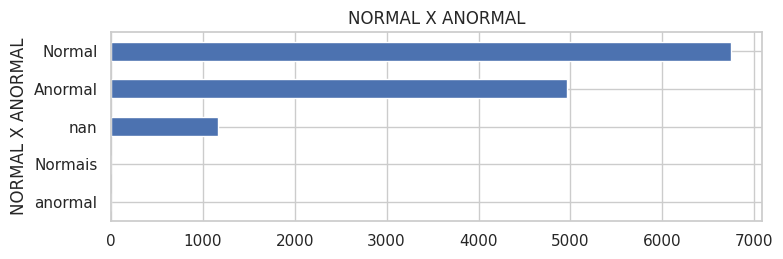

In [ ]:
univariada('NORMAL X ANORMAL')

In [ ]:
# Limpeza de 'NORMAL X ANORMAL'
# Problemas encontrados: grande número de nulos e escritas diferentes.
antes = df['NORMAL X ANORMAL'].copy()
df['NORMAL X ANORMAL'] = df['NORMAL X ANORMAL'].replace({'Normais': 'Normal', 'anormal': 'Anormal'})
alterados = antes.notna() & (antes != df['NORMAL X ANORMAL'])
registrar('NORMAL X ANORMAL',
          problema="Mesma classe com grafias diferentes ('Normais', 'anormal')",
          qtd_afetada=int(alterados.sum()),
          solucao="Padronização para 'Normal' e 'Anormal'",
          justificativa='Grafias diferentes seriam tratadas como classes distintas do alvo')

# Os registros sem alvo NÃO são removidos aqui (regra do notebook): a remoção está na seção 6.
sem_alvo = df['NORMAL X ANORMAL'].isna()
print('Grafias corrigidas:', alterados.sum(), '| Sem alvo (removidos na seção 6):', sem_alvo.sum())
print(df['NORMAL X ANORMAL'].value_counts(dropna=False))
#Solução: padronizar as classes escritas diferentes de acordo com as predominantes e criar uma classe para os valores ausentes.
#Justificativa: Como se trata do alvo, imputar um resultado não pode ser feito, pois não há como ter certeza de qualquer resultado

Grafias corrigidas: 2 | Sem alvo (removidos na seção 6): 1168
NORMAL X ANORMAL
Normal     6745
Anormal    4960
NaN        1168
Name: count, dtype: int64


### FC
**Problemas já identificados:** Lida como texto: intervalos ('80-90', '156 a 168'); valores impossíveis (8, 9288).

--- FC | ausentes: 1868 (14.5%) | distintos: 118


,contagem
FC,
NaN,1868
100,1509
80,1480
90,1104
88,832
96,782
120,780
92,599
72,456


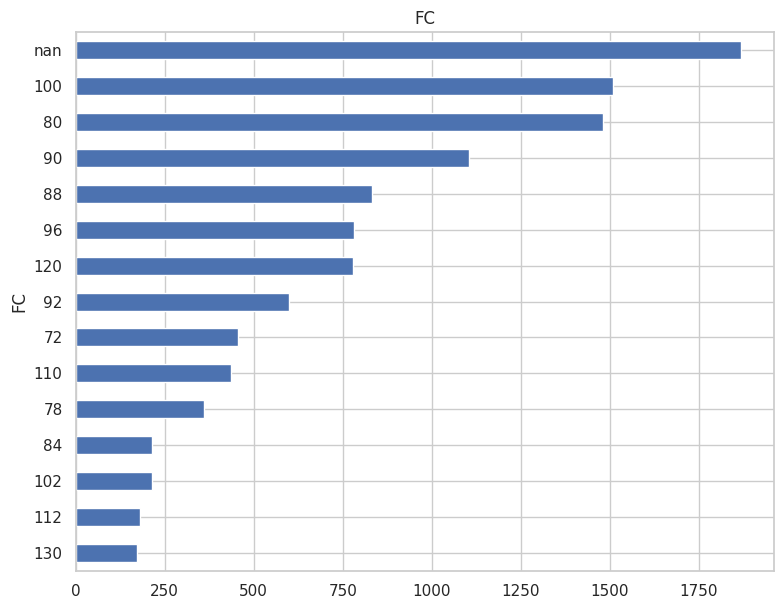

In [ ]:
univariada('FC')

In [ ]:
# Limpeza de 'FC'
import re

fc_txt = df['FC']
fc = pd.to_numeric(fc_txt, errors='coerce')

# 1) Faixas registradas como texto ('80-90', '156 a 168') -> ponto médio
def ponto_medio(valor):
    numeros = [float(n) for n in re.findall(r'\d+', str(valor))]
    return np.mean(numeros) if len(numeros) == 2 else np.nan

faixa_txt = fc_txt.notna() & fc.isna()
fc[faixa_txt] = fc_txt[faixa_txt].map(ponto_medio)
registrar('FC', "Valor registrado como faixa em texto (ex.: '80-90', '156 a 168')", int(faixa_txt.sum()),
          'Convertido para o ponto médio da faixa',
          'Aproveita a medida registrada; o erro máximo é metade da amplitude da faixa')

# 2) Valores fisiologicamente impossíveis -> ausente
fora = (fc < 30) | (fc > 300)
fc[fora] = np.nan
registrar('FC', 'Valor fora da faixa fisiológica (< 30 ou > 300 bpm; ex.: 8, 10, 9288)', int(fora.sum()),
          'Convertido para ausente',
          'Não é possível recuperar o valor correto com segurança qualquer imputação seria especulação')

df['FC'] = fc.round(0)

# 3) Ausentes: NÃO imputar; criar indicador de não coleta
df['FC_AUSENTE'] = df['FC'].isna().astype(int)
registrar('FC', 'FC ausente (original ou gerada pelas regras acima)', int(df['FC_AUSENTE'].sum()),
          'Mantida vazia (sem imputação) + indicador FC_AUSENTE',
          'A FC é um dado diagnóstico: um valor imputado não corresponderia ao estado do paciente; '
          'o indicador registra que a medida não foi coletada')

print('Faixas -> ponto médio:', faixa_txt.sum(), '| Fora de 30-300 -> ausente:', fora.sum(),
      '| Ausentes finais:', df['FC'].isna().sum())
print(df['FC'].describe().round(1))

Faixas -> ponto médio: 16 | Fora de 30-300 -> ausente: 14 | Ausentes finais: 1882
count    10991.0
mean        95.3
std         18.1
min         43.0
25%         80.0
50%         92.0
75%        100.0
max        300.0
Name: FC, dtype: float64


### PULSOS
**Problemas já identificados:** Grafias diferentes ('Normais'/'NORMAIS', espaços no final).

--- PULSOS | ausentes: 1194 (9.3%) | distintos: 7


,contagem
PULSOS,
Normais,11531
NaN,1194
Amplos,52
Femorais diminuidos,39
Outro,36
Diminuídos,18
NORMAIS,2
AMPLOS,1


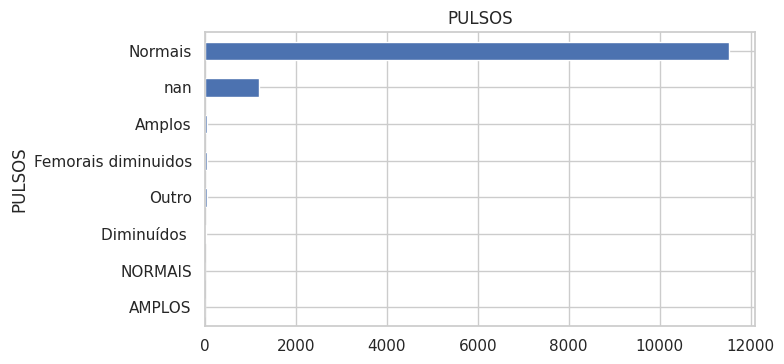

In [ ]:
univariada('PULSOS')

In [ ]:
# Limpeza de 'PULSOS'
antes = df['PULSOS'].copy()
df['PULSOS'] = df['PULSOS'].replace({'NORMAIS': 'Normais', 'AMPLOS': 'Amplos', 'Diminuídos ': 'Diminuídos',
                                     'Femorais diminuidos': 'Femorais diminuídos'})
alterados = antes.notna() & (antes != df['PULSOS'])
registrar('PULSOS', "Grafias diferentes ('NORMAIS', 'AMPLOS', espaço no final, falta de acento)", int(alterados.sum()),
          'Padronização da grafia', 'Grafias diferentes seriam tratadas como categorias distintas')

nulos = df['PULSOS'].isna()
df['PULSOS'] = df['PULSOS'].fillna('Não informado')
registrar('PULSOS', 'Pulsos não registrados', int(nulos.sum()),
          "Categoria 'Não informado'",
          "Dado diagnóstico: imputar 'Normais' afirmaria um achado de exame que não foi feito")

print('Grafias corrigidas:', alterados.sum(), '| Não informado:', nulos.sum())
print(df['PULSOS'].value_counts())

Grafias corrigidas: 60 | Não informado: 1194
PULSOS
Normais                11533
Não informado           1194
Amplos                    53
Femorais diminuídos       39
Outro                     36
Diminuídos                18
Name: count, dtype: int64


### B2
**Problemas já identificados:** Conferir categorias e grafia.

--- B2 | ausentes: 1178 (9.2%) | distintos: 5


,contagem
B2,
Normal,11098
NaN,1178
Hiperfonética,295
Desdob fixo,149
Única,77
Outro,76


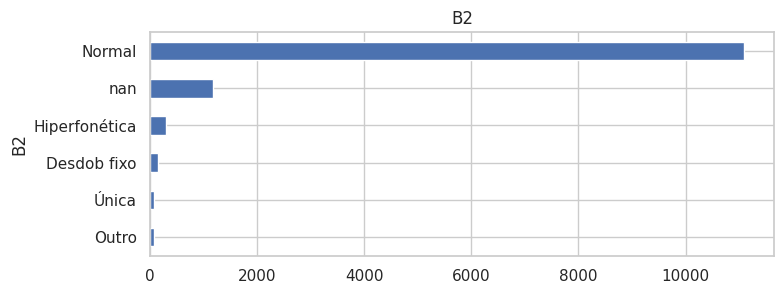

In [ ]:
univariada('B2')

In [ ]:
# Limpeza de 'B2'
antes = df['B2'].copy()
df['B2'] = df['B2'].replace({'Desdob fixo': 'Desdobramento fixo'})
alterados = antes.notna() & (antes != df['B2'])
registrar('B2', "Categoria abreviada ('Desdob fixo')", int(alterados.sum()),
          "Renomeada para 'Desdobramento fixo'", 'Clareza na análise e no relatório')

nulos = df['B2'].isna()
df['B2'] = df['B2'].fillna('Não informado')
registrar('B2', 'Segunda bulha não registrada', int(nulos.sum()),
          "Categoria 'Não informado' (sem imputação)",
          "Dado diagnóstico: imputar 'Normal' afirmaria um achado de ausculta que não foi registrado")

print('Renomeados:', alterados.sum(), '| Não informado:', nulos.sum())
print(df['B2'].value_counts())

Renomeados: 149 | Não informado: 1178
B2
Normal                11098
Não informado          1178
Hiperfonética           295
Desdobramento fixo      149
Única                    77
Outro                    76
Name: count, dtype: int64


### SOPRO
**Problemas já identificados:** Grafias diferentes ('Sistólico'/'sistólico'...). Forte relação com o alvo.

--- SOPRO | ausentes: 1167 (9.1%) | distintos: 7


,contagem
SOPRO,
ausente,7275
Sistólico,3648
NaN,1167
sistólico,723
contínuo,28
Contínuo,20
diastólico,9
Sistolico e diastólico,3


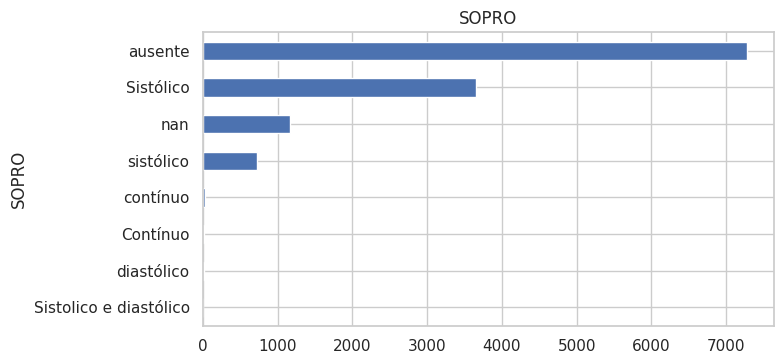

In [ ]:
univariada('SOPRO')

In [ ]:
# Limpeza de 'SOPRO'
antes = df['SOPRO'].copy()
df['SOPRO'] = df['SOPRO'].replace({'ausente': 'Ausente', 'sistólico': 'Sistólico', 'contínuo': 'Contínuo',
                                   'diastólico': 'Diastólico', 'Sistolico e diastólico': 'Sistólico e diastólico'})
duplicadas = antes.isin(['sistólico', 'contínuo'])
cosmeticas = antes.notna() & (antes != df['SOPRO']) & ~duplicadas
registrar('SOPRO', "Mesma categoria duplicada por maiúscula/minúscula ('sistólico'/'Sistólico', 'contínuo'/'Contínuo')",
          int(duplicadas.sum()), 'Unificação das categorias',
          'Sem a correção, o sopro sistólico seria subestimado em cerca de 17%')
registrar('SOPRO', "Grafia fora do padrão ('ausente', 'diastólico', 'Sistolico e diastólico')", int(cosmeticas.sum()),
          'Padronização da grafia', 'Uniformidade dos rótulos')

nulos = df['SOPRO'].isna()
df['SOPRO'] = df['SOPRO'].fillna('Não informado')
registrar('SOPRO', 'Sopro não registrado', int(nulos.sum()),
          "Categoria 'Não informado' (sem imputação)",
          "Dado diagnóstico: não coletar o sopro não equivale a não ter sopro (esses casos têm 30% de Anormal, "
          "contra 10% dos sopros ausentes)")

print('Duplicadas unificadas:', duplicadas.sum(), '| Grafias padronizadas:', cosmeticas.sum(), '| Não informado:', nulos.sum())
print(df['SOPRO'].value_counts())

Duplicadas unificadas: 751 | Grafias padronizadas: 7287 | Não informado: 1167
SOPRO
Ausente                   7275
Sistólico                 4371
Não informado             1167
Contínuo                    48
Diastólico                   9
Sistólico e diastólico       3
Name: count, dtype: int64


### HDA 1
**Problemas já identificados:** Conferir categorias e grafia.

--- HDA 1 | ausentes: 4270 (33.2%) | distintos: 8


,contagem
HDA 1,
Assintomático,6561
NaN,4270
Dispneia,541
Dor precordial,508
Palpitacao,365
Cianose,260
Desmaio/tontura,157
Outro,124
Ganho de peso,87


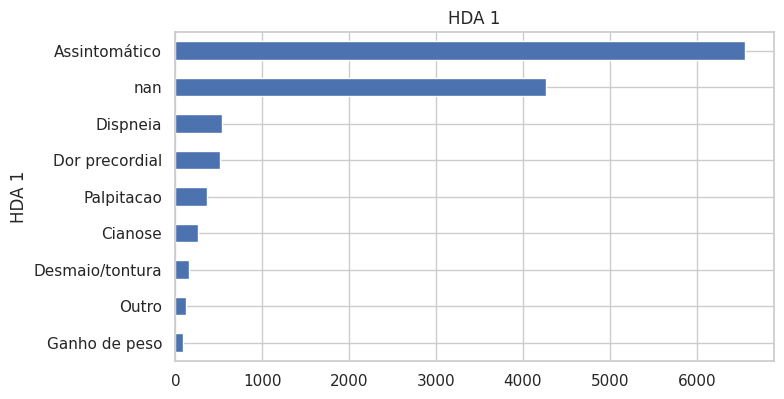

In [ ]:
univariada('HDA 1')

### HDA2
**Problemas já identificados:** 97% vazio. Avaliar manter ou descartar.

--- HDA2 | ausentes: 12466 (96.8%) | distintos: 8


,contagem
HDA2,
NaN,12466
Dispneia,83
Palpitacao,83
Dor precordial,65
Cianose,65
Desmaio/tontura,50
Outro,41
Ganho de peso,19
Assintomático,1


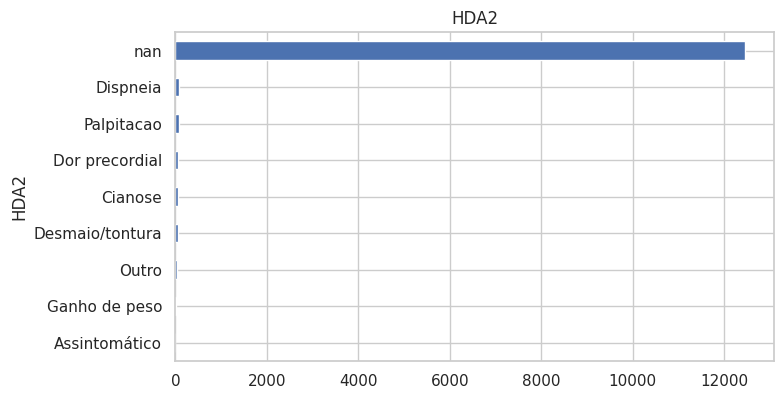

In [ ]:
univariada('HDA2')

In [ ]:
# Limpeza de 'HDA 1' e 'HDA2' (tratadas juntas: são duas posições da mesma informação)
h1 = df['HDA 1'].replace({'Palpitacao': 'Palpitação'})
h2 = df['HDA2'].replace({'Palpitacao': 'Palpitação'})
grafia = int((df['HDA 1'] == 'Palpitacao').sum() + (df['HDA2'] == 'Palpitacao').sum())
registrar('HDA 1 / HDA2', "Grafia sem acento ('Palpitacao')", grafia,
          "Corrigido para 'Palpitação'", 'Uniformidade dos rótulos')

mover = h1.isna() & h2.notna()
h1[mover], h2[mover] = h2[mover], np.nan
registrar('HDA 1 / HDA2', 'HDA2 preenchida com HDA 1 vazia', int(mover.sum()),
          'Valor movido para HDA 1', 'HDA 1 é a posição principal do sintoma')

duplicado = h1.notna() & (h1 == h2)
h2[duplicado] = np.nan
registrar('HDA 1 / HDA2', 'Mesmo sintoma nas duas colunas', int(duplicado.sum()),
          'HDA2 descartada', 'Duplicata: não acrescenta informação')

contradicao = (h1 == 'Assintomático') & h2.notna()
h1[contradicao], h2[contradicao] = h2[contradicao], np.nan
registrar('HDA 1 / HDA2', "'Assintomático' junto de um sintoma", int(contradicao.sum()),
          'Mantido apenas o sintoma', 'Contradição lógica: se há sintoma, o paciente não é assintomático')

nulos_h1, nulos_h2 = int(h1.isna().sum()), int(h2.isna().sum())
df['HDA 1'], df['HDA2'] = h1.fillna('Não informado'), h2.fillna('Nenhum')
registrar('HDA 1', 'Anamnese não registrada', nulos_h1, "Categoria 'Não informado' (sem imputação)",
          "Nulo não equivale a 'Assintomático': esses casos têm 34% de Anormal, contra 47% dos assintomáticos")
registrar('HDA2', 'HDA2 vazia', nulos_h2, "Categoria 'Nenhum'",
          'Nulo estrutural: indica que não houve segundo sintoma, não um dado perdido')

print(df['HDA 1'].value_counts())
print(df['HDA2'].value_counts())

HDA 1
Assintomático      6561
Não informado      4269
Dispneia            541
Dor precordial      508
Palpitação          366
Cianose             260
Desmaio/tontura     157
Outro               124
Ganho de peso        87
Name: count, dtype: int64
HDA2
Nenhum             12471
Dispneia              82
Palpitação            82
Dor precordial        65
Cianose               65
Desmaio/tontura       50
Outro                 39
Ganho de peso         19
Name: count, dtype: int64


### MOTIVO1
**Problemas já identificados:** Conferir categorias e grafia.

--- MOTIVO1 | ausentes: 1055 (8.2%) | distintos: 5


,contagem
MOTIVO1,
5 - Parecer cardiológico,5352
6 - Suspeita de cardiopatia,4285
1 - Cardiopatia já estabelecida,1158
NaN,1055
2 - Check-up,701
7 - Outro,322


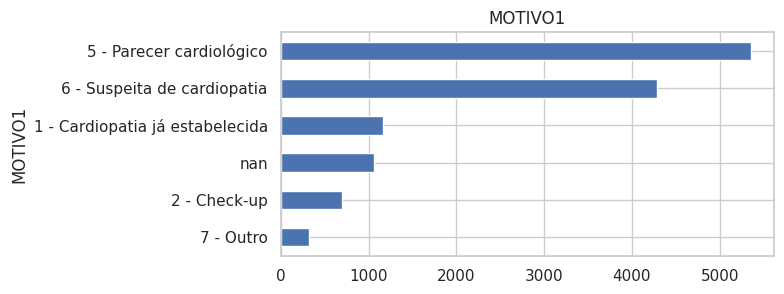

In [ ]:
univariada('MOTIVO1')

### MOTIVO2
**Problemas já identificados:** Prefixos numéricos inconsistentes entre categorias.

--- MOTIVO2 | ausentes: 3496 (27.2%) | distintos: 16


,contagem
MOTIVO2,
NaN,3496
5 - Cirurgia,2940
6 - Sopro,2349
1 - Cardiopatia congenica,1041
Outro,824
5 - Atividade física,652
6 - Palpitação/taquicardia/arritmia,415
6 - Dor precordial,392
6 - HAS/dislipidemia/obesidade,240


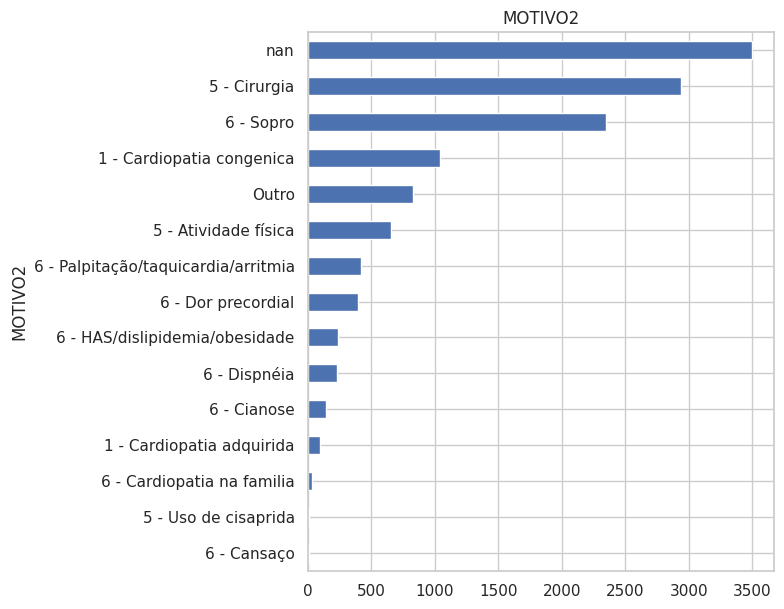

In [ ]:
univariada('MOTIVO2')

In [ ]:
# Limpeza de 'MOTIVO1' e 'MOTIVO2'
antes = df['MOTIVO2'].copy()
df['MOTIVO2'] = df['MOTIVO2'].replace({'1 - Cardiopatia congenica': '1 - Cardiopatia congênita',
                                       '6 - Cardiopatia na familia': '6 - Cardiopatia na família'})
alterados = antes.notna() & (antes != df['MOTIVO2'])
registrar('MOTIVO2', "Grafia sem acento ('congenica', 'familia')", int(alterados.sum()),
          'Padronização da grafia', 'Uniformidade dos rótulos')

cod1 = df['MOTIVO1'].str.extract(r'^(\d)')[0]
cod2 = df['MOTIVO2'].str.extract(r'^(\d)')[0]
inconsistente = cod1.notna() & cod2.notna() & (cod1 != cod2)
registrar('MOTIVO2', 'Código da subcategoria diferente do código de MOTIVO1', int(inconsistente.sum()),
          'Valores mantidos',
          'Não é possível saber qual campo está errado; a inconsistência não tem relação com o alvo (p = 0,41)')

m1_nulo = df['MOTIVO1'].isna()
sem_sub = df['MOTIVO2'].isna() & (cod1.isin(['2', '7']) | m1_nulo)
m2_nulo = df['MOTIVO2'].isna() & ~sem_sub
df.loc[sem_sub, 'MOTIVO2'] = 'Sem subcategoria'
df['MOTIVO2'] = df['MOTIVO2'].fillna('Não informado')
df['MOTIVO1'] = df['MOTIVO1'].fillna('Não informado')
registrar('MOTIVO1', 'Motivo não registrado', int(m1_nulo.sum()), "Categoria 'Não informado'",
          'Mantém o registro sem inventar o motivo da consulta')
registrar('MOTIVO2', 'Vazio quando MOTIVO1 não tem subcategorias (Check-up, Outro ou vazio)', int(sem_sub.sum()),
          "Categoria 'Sem subcategoria'", 'Nulo estrutural, não é dado perdido')
registrar('MOTIVO2', 'Vazio quando MOTIVO1 exige subcategoria (1, 5 ou 6)', int(m2_nulo.sum()),
          "Categoria 'Não informado'", 'Dado realmente não registrado')

print(df['MOTIVO1'].value_counts())
print(df['MOTIVO2'].value_counts())

MOTIVO1
5 - Parecer cardiológico           5352
6 - Suspeita de cardiopatia        4285
1 - Cardiopatia já estabelecida    1158
Não informado                      1055
2 - Check-up                        701
7 - Outro                           322
Name: count, dtype: int64
MOTIVO2
5 - Cirurgia                           2940
6 - Sopro                              2349
Não informado                          1770
Sem subcategoria                       1726
1 - Cardiopatia congênita              1041
Outro                                   824
5 - Atividade física                    652
6 - Palpitação/taquicardia/arritmia     415
6 - Dor precordial                      392
6 - HAS/dislipidemia/obesidade          240
6 - Dispnéia                            226
6 - Cianose                             145
1 - Cardiopatia adquirida                92
6 - Cardiopatia na família               35
5 - Uso de cisaprida                      9
6 - Cansaço                               7
6 - Alterações

## 6. Decisões conjuntas (combinar no grupo antes de executar)
Remoções de linhas que afetam todas as colunas, por exemplo:
- linhas sem variável-alvo;
- idade fora da faixa de 0 a 19 anos após a limpeza;
- registros praticamente vazios.

In [ ]:
antes = len(df)
# TODO: remoções combinadas no grupo, com registrar(...) para cada uma
# Removi a as duplicatas e linhas sem alvos referentes a parte 3
VARIAVEIS_ESTUDO = ['NORMAL X ANORMAL', 'FC', 'PULSOS', 'B2', 'SOPRO', 'HDA 1', 'HDA2', 'MOTIVO1', 'MOTIVO2']

sem_alvo = df['NORMAL X ANORMAL'].isna()
duplicado = df.drop(columns='ID').duplicated(keep='first')   # igual a um registro anterior em tudo, menos no ID

criterios = {'Sem variável-alvo': sem_alvo, 'Registro duplicado (todas as colunas exceto ID)': duplicado}

ja_marcado = pd.Series(False, index=df.index)
resumo = []
for nome, mascara in criterios.items():
    resumo.append({'critério': nome, 'registros atingidos': int(mascara.sum()),
                   'removidos por este critério': int((mascara & ~ja_marcado).sum())})
    ja_marcado |= mascara
justificativas = {
    'Sem variável-alvo': 'Não se imputa o alvo em aprendizado supervisionado; a maioria desses registros é ficha vazia',
    'Registro duplicado (todas as colunas exceto ID)': 'Mesmo atendimento cadastrado mais de uma vez com IDs diferentes; '
                                                       'manter as cópias daria peso dobrado a esses pacientes',
}
antes = len(df)
dist_antes = df['NORMAL X ANORMAL'].value_counts(normalize=True)

# Contagens exclusivas: a duplicata só conta se ainda não saiu por falta de alvo
qtd_sem_alvo = int(sem_alvo.sum())
qtd_duplicado = int((duplicado & ~sem_alvo).sum())

registrar('NORMAL X ANORMAL',
          problema='Registro sem variável-alvo',
          qtd_afetada=qtd_sem_alvo,
          solucao='Linha removida',
          justificativa='Não se imputa o alvo em aprendizado supervisionado; '
                        'a maioria desses registros é ficha sem nenhum dado clínico')

registrar('Todas as colunas (exceto ID)',
          problema='Registro duplicado: mesmo atendimento cadastrado mais de uma vez com IDs diferentes',
          qtd_afetada=qtd_duplicado,
          solucao='Linha removida (mantida a primeira ocorrência)',
          justificativa='As cópias dariam peso dobrado ao mesmo paciente na análise e na modelagem; '
                        f'outras {int((duplicado & sem_alvo).sum())} duplicatas já saíram por não terem alvo')

df = df[~(sem_alvo | duplicado)].reset_index(drop=True)

print(f'Linhas: {antes} -> {len(df)} ({antes - len(df)} removidas: '
      f'{qtd_sem_alvo} sem alvo + {qtd_duplicado} duplicadas)')
display(pd.DataFrame(log).tail(2))   # confere o que foi registrado
display(pd.DataFrame({'antes (%)': dist_antes * 100,
                      'depois (%)': df['NORMAL X ANORMAL'].value_counts(normalize=True) * 100}).round(1))

print(f'Linhas: {antes} -> {len(df)}')

# Atendimento fora do período da coleta -> idade ausente (antes do filtro de idade)
ANO_MAX = 2010   # conferir com df['Atendimento'].dt.year.value_counts().sort_index()
data_invalida = df['Atendimento'].dt.year > ANO_MAX
df.loc[data_invalida, 'IDADE'] = np.nan
registrar('IDADE', 'Data de atendimento fora do período da coleta', int(data_invalida.sum()),
          'Idade convertida para ausente', 'Idade calculada a partir de data inválida não é confiável')

#Pacientes fora do escopo (20 anos ou mais)
adultos = df['IDADE'] >= 20
df = df[~adultos].reset_index(drop=True)
registrar('Linhas', 'Pacientes com 20 anos ou mais', int(adultos.sum()), 'Removidos',
          'Fora do escopo do estudo (0 a 19 anos); peso, altura e datas coerentes indicam adultos reais, não erros')

print(f'Data inválida -> idade ausente: {data_invalida.sum()} | Adultos removidos: {adultos.sum()}')
print(f'Linhas finais: {len(df)}')

Linhas: 12873 -> 11463 (1410 removidas: 1168 sem alvo + 242 duplicadas)


,variavel,problema,qtd_afetada,solucao,justificativa
47,NORMAL X ANORMAL,Registro sem variável-alvo,1168,Linha removida,Não se imputa o alvo em aprendizado supervisio...
48,Todas as colunas (exceto ID),Registro duplicado: mesmo atendimento cadastra...,242,Linha removida (mantida a primeira ocorrência),As cópias dariam peso dobrado ao mesmo pacient...


,antes (%),depois (%)
NORMAL X ANORMAL,,
Normal,57.6,57.4
Anormal,42.4,42.6


Linhas: 12873 -> 11463
Data inválida -> idade ausente: 1 | Adultos removidos: 61
Linhas finais: 11402


## 6.1 Tabelas do relatório: Bloco 1


In [ ]:
# Relatório - tabela univariada das numéricas (antes x depois)
num = ['Peso', 'Altura', 'IMC']
def resumo(d, rotulo):
    t = d[num].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
    t['% ausentes'] = d[num].isna().mean() * 100
    t.insert(0, 'etapa', rotulo)
    return t
tab = pd.concat([resumo(df_raw, 'Bruto'), resumo(df, 'Limpo')]).round(1)
tab.index.name = 'variável'
tab.reset_index().sort_values(['variável', 'etapa'])

,variável,etapa,count,mean,std,min,50%,max,% ausentes
1,Altura,Bruto,12873.0,66.1,56.0,0.0,69.0,198.0,0.0
4,Altura,Limpo,7933.0,100.4,34.9,36.0,99.0,198.0,30.4
2,IMC,Bruto,8146.0,17.5,15.0,0.0,17.0,848.0,36.7
5,IMC,Limpo,7560.0,17.3,3.4,8.6,16.7,44.6,33.7
0,Peso,Bruto,12555.0,16.6,17.0,-40.0,12.8,157.0,2.5
3,Peso,Limpo,9437.0,20.5,16.0,0.3,16.0,157.0,17.2


In [ ]:
# Relatório - tabela das categóricas (antes x depois)
linhas = []
for col in ['SEXO', 'Convenio']:
    for rotulo, d in [('Bruto', df_raw), ('Limpo', df)]:
        vc = d[col].value_counts()
        linhas.append({'variável': col, 'etapa': rotulo, 'categorias': d[col].nunique(),
                       'mais frequente': f'{vc.index[0]} ({vc.iloc[0]})',
                       '% ausentes': round(d[col].isna().mean() * 100, 1)})
pd.DataFrame(linhas)

,variável,etapa,categorias,mais frequente,% ausentes
0,SEXO,Bruto,6,M (6065),0.0
1,SEXO,Limpo,2,M (6425),4.6
2,Convenio,Bruto,374,GS (2094),31.9
3,Convenio,Limpo,31,GS (1982),27.6


In [ ]:
pd.DataFrame(log).query("variavel in ['Peso', 'Altura', 'IMC', 'SEXO', 'Convenio']")

,variavel,problema,qtd_afetada,solucao,justificativa
0,Peso,Peso igual a 0 (representa ausência de medição),2609,Convertido para ausente,Peso zero é fisicamente impossível; o zero foi...
1,Peso,Peso negativo,1,Convertido para ausente,"Valor fisicamente impossível, provável erro de..."
2,Altura,Altura igual a 0 (representa ausência de medição),4460,Convertido para ausente,Altura zero é fisicamente impossível; o zero f...
3,Altura,Altura abaixo de 30 cm,6,Convertido para ausente,Abaixo do tamanho de um recém-nascido prematur...
4,IMC,IMC ausente com peso e altura disponíveis,0,Recalculado como Peso / (Altura/100)²,O IMC é derivado de peso e altura; recalcular ...
5,IMC,IMC divergente do calculado a partir de peso e...,125,Substituído pelo valor recalculado,Garante consistência entre as três variáveis a...
6,IMC,IMC informado sem peso ou altura válidos,114,Convertido para ausente,Sem peso e altura válidos não é possível verif...
7,IMC,IMC fora da faixa plausível (8 a 50),22,Convertido para ausente; peso e altura desses ...,Valores fora dessa faixa indicam erro em peso ...
8,SEXO,Mesma categoria com grafias diferentes ('Mascu...,910,Padronização para 'M' e 'F',Grafias diferentes seriam tratadas como catego...
9,SEXO,Categoria 'Indeterminado' representando ausênc...,1417,Convertido para ausente,Registros com esse valor são majoritariamente ...


## 7. Log de decisões (base para o relatório)

In [ ]:
log_df = pd.DataFrame(log)
log_df

,variavel,problema,qtd_afetada,solucao,justificativa
0,Peso,Peso igual a 0 (representa ausência de medição),2609,Convertido para ausente,Peso zero é fisicamente impossível; o zero foi...
1,Peso,Peso negativo,1,Convertido para ausente,"Valor fisicamente impossível, provável erro de..."
2,Altura,Altura igual a 0 (representa ausência de medição),4460,Convertido para ausente,Altura zero é fisicamente impossível; o zero f...
3,Altura,Altura abaixo de 30 cm,6,Convertido para ausente,Abaixo do tamanho de um recém-nascido prematur...
4,IMC,IMC ausente com peso e altura disponíveis,0,Recalculado como Peso / (Altura/100)²,O IMC é derivado de peso e altura; recalcular ...
5,IMC,IMC divergente do calculado a partir de peso e...,125,Substituído pelo valor recalculado,Garante consistência entre as três variáveis a...
6,IMC,IMC informado sem peso ou altura válidos,114,Convertido para ausente,Sem peso e altura válidos não é possível verif...
7,IMC,IMC fora da faixa plausível (8 a 50),22,Convertido para ausente; peso e altura desses ...,Valores fora dessa faixa indicam erro em peso ...
8,SEXO,Mesma categoria com grafias diferentes ('Mascu...,910,Padronização para 'M' e 'F',Grafias diferentes seriam tratadas como catego...
9,SEXO,Categoria 'Indeterminado' representando ausênc...,1417,Convertido para ausente,Registros com esse valor são majoritariamente ...


## 8. Salvar o dataset limpo

In [ ]:
PASTA = CAMINHO.rsplit('/', 1)[0] + '/' if CAMINHO.startswith('/content/drive') else ''
df.to_csv(PASTA + 'UCMF_limpo.csv', index=False)
log_df.to_csv(PASTA + 'log_decisoes.csv', index=False)
print('Salvo:', df.shape)

Salvo: (11402, 22)


## 9. Análises após a limpeza (em conjunto)
### 9.1 Comparação de duas variáveis limpas + interpretação gráfica
 Peso × Altura


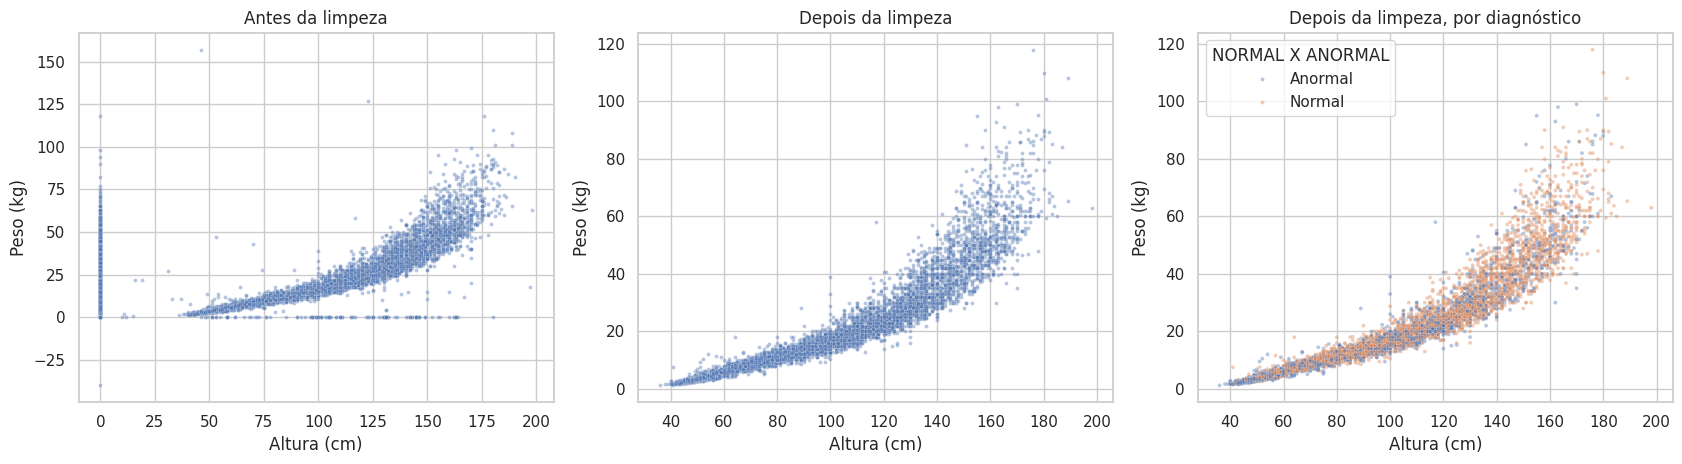

Bruto: 12555 pares válidos | Spearman = 0.709 | Pearson = 0.643
Limpo: 7560 pares válidos | Spearman = 0.984 | Pearson = 0.917


In [ ]:
# Exemplo: dispersão entre duas variáveis, colorida pelo alvo
# sns.scatterplot(data=df, x='Altura', y='Peso', hue='NORMAL X ANORMAL', alpha=0.4)
# 9.1 Comparação Peso x Altura: bruto x limpo
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

sns.scatterplot(data=df_raw, x='Altura', y='Peso', s=8, alpha=0.4, ax=ax[0])
ax[0].set_title('Antes da limpeza')

sns.scatterplot(data=df, x='Altura', y='Peso', s=8, alpha=0.4, ax=ax[1])
ax[1].set_title('Depois da limpeza')

sns.scatterplot(data=df, x='Altura', y='Peso', hue='NORMAL X ANORMAL', s=8, alpha=0.4, ax=ax[2])
ax[2].set_title('Depois da limpeza, por diagnóstico')

for a in ax:
    a.set_xlabel('Altura (cm)'); a.set_ylabel('Peso (kg)')
plt.tight_layout(); plt.show()

for nome, d in [('Bruto', df_raw), ('Limpo', df)]:
    pares = d[['Peso', 'Altura']].dropna()
    print(f'{nome}: {len(pares)} pares válidos | Spearman = {pares.corr("spearman").iloc[0, 1]:.3f} '
          f'| Pearson = {pares.corr("pearson").iloc[0, 1]:.3f}')

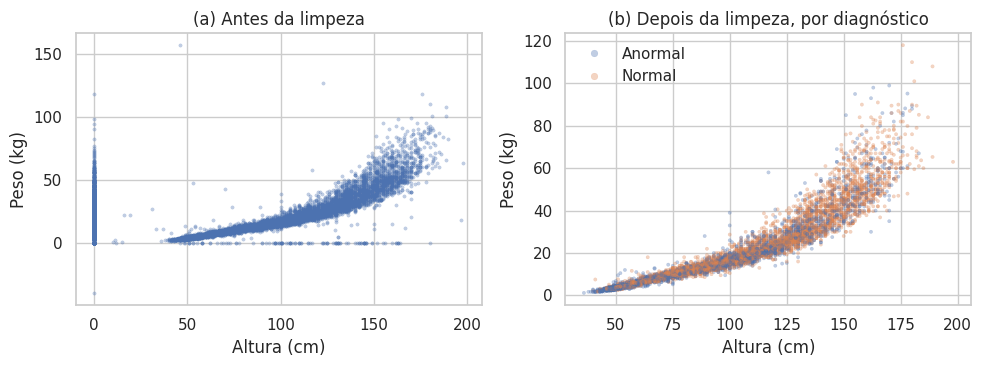

In [ ]:
# Figura para o relatório: Peso x Altura antes e depois da limpeza
plt.rcParams.update({'font.size': 11})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

sns.scatterplot(data=df_raw, x='Altura', y='Peso', s=6, alpha=0.35, ax=ax[0], edgecolor=None)
ax[0].set_title('(a) Antes da limpeza')
sns.scatterplot(data=df, x='Altura', y='Peso', hue='NORMAL X ANORMAL', s=6, alpha=0.35,
                ax=ax[1], edgecolor=None)
ax[1].set_title('(b) Depois da limpeza, por diagnóstico')
ax[1].legend(title=None, markerscale=2, frameon=False)

for a in ax:
    a.set_xlabel('Altura (cm)'); a.set_ylabel('Peso (kg)')
plt.tight_layout()
fig.savefig(PASTA + 'fig_peso_altura.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.2 Análise bivariada: cada variável × alvo

In [ ]:
ALVO = 'NORMAL X ANORMAL'

def bivariada(col):
    if pd.api.types.is_numeric_dtype(df[col]):
        display(df.groupby(ALVO)[col].describe().round(2))
        sns.boxplot(data=df, x=ALVO, y=col); plt.title(f'{col} por {ALVO}')
    else:
        tab = pd.crosstab(df[col], df[ALVO], normalize='index').round(2)
        display(tab)
        tab.plot.barh(stacked=True, figsize=(8, 0.35 * len(tab) + 1), title=f'{col} × {ALVO}')
    plt.tight_layout(); plt.show()

#for c in df.columns.drop(['ID', ALVO]): bivariada(c)


In [ ]:
# 9.2 Análise bivariada: cada variável × alvo (sobre o df limpo)
from scipy.stats import chi2_contingency, mannwhitneyu

ALVO = 'NORMAL X ANORMAL'
TAXA_GLOBAL = (df[ALVO] == 'Anormal').mean() * 100
FAIXAS = [0, 1, 3, 6, 13, 20]
faixa_etaria = pd.cut(df['IDADE'], FAIXAS, right=False,
                      labels=['<1 ano', '1-2 anos', '3-5 anos', '6-12 anos', '13-19 anos'])

def forca(v):
    return 'desprezível' if v < 0.1 else 'fraca' if v < 0.2 else 'moderada' if v < 0.4 else 'forte'

def teste_categorica(col, serie=None):
    # Qui-quadrado + V de Cramér; ausentes entram como categoria para não sumirem da análise
    s = (df[col] if serie is None else serie).fillna('Não informado')
    tab = pd.crosstab(s, df[ALVO])
    chi2, p, gl, esperado = chi2_contingency(tab, correction=False)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    detalhe = pd.DataFrame({'n': tab.sum(axis=1),
                            '% Anormal': (tab['Anormal'] / tab.sum(axis=1) * 100).round(1)})
    detalhe = detalhe.sort_values('% Anormal', ascending=False)
    return dict(variavel=col, tipo='categórica', teste='Qui-quadrado', estatistica=round(chi2, 1), gl=gl,
                p_valor=p, efeito=round(v, 3), medida='V de Cramér', forca=forca(v),
                pct_esperado_menor_5=round((esperado < 5).mean() * 100, 1)), detalhe

def mann_whitney(valores, alvo):
    a, b = valores[alvo == 'Anormal'], valores[alvo == 'Normal']
    u, p = mannwhitneyu(a, b)
    prob = u / (len(a) * len(b))          # P(Anormal > Normal), empates contam meio
    return u, p, prob, 2 * prob - 1, a.median(), b.median(), len(a) + len(b)

def teste_numerica(col, ajustar_idade=True):
    d = df[[col, ALVO]].dropna()
    u, p, prob, r, med_a, med_n, n = mann_whitney(d[col], d[ALVO])
    linhas = [dict(variavel=col, tipo='numérica', teste='Mann-Whitney', estatistica=round(u, 0), gl=np.nan,
                   p_valor=p, efeito=round(abs(r), 3), medida='|r| rank-bisserial', forca=forca(abs(r)),
                   pct_esperado_menor_5=np.nan, n=n, mediana_anormal=med_a, mediana_normal=med_n,
                   p_anormal_maior=round(prob, 3))]
    if ajustar_idade:
        # mesmo teste com o valor padronizado dentro da faixa etária (remove o efeito de confusão da idade)
        z = df[col].groupby(faixa_etaria, observed=True).transform(lambda s: (s - s.mean()) / s.std())
        dz = pd.DataFrame({'z': z, ALVO: df[ALVO]}).dropna()
        u, p, prob, r, _, _, n = mann_whitney(dz['z'], dz[ALVO])
        linhas.append(dict(variavel=f'{col} (ajustada por idade)', tipo='numérica', teste='Mann-Whitney',
                           estatistica=round(u, 0), gl=np.nan, p_valor=p, efeito=round(abs(r), 3),
                           medida='|r| rank-bisserial', forca=forca(abs(r)), pct_esperado_menor_5=np.nan,
                           n=n, p_anormal_maior=round(prob, 3)))
    # a ausência do dado também é testada contra o alvo
    ausente = df[col].isna().map({True: 'Ausente', False: 'Registrado'})
    if df[col].isna().any():
        res, _ = teste_categorica(f'{col} (ausente x registrado)', ausente)
        linhas.append(res)
    return linhas

resultados, detalhes = [], {}
for col in ['SEXO', 'Convenio', 'PPA', 'PULSOS', 'B2', 'SOPRO', 'HDA 1', 'HDA2', 'MOTIVO1', 'MOTIVO2']:
    res, det = teste_categorica(col)
    resultados.append(res); detalhes[col] = det
for col in ['IDADE', 'Peso', 'Altura', 'IMC', 'PA SISTOLICA', 'PA DIASTOLICA', 'FC']:
    resultados += teste_numerica(col, ajustar_idade=(col != 'IDADE'))

resumo_bivariada = pd.DataFrame(resultados).sort_values('efeito', ascending=False)
resumo_bivariada['p_valor'] = resumo_bivariada['p_valor'].map(lambda p: f'{p:.1e}')
print(f'Taxa global de Anormal: {TAXA_GLOBAL:.1f}%')
display(resumo_bivariada)

Taxa global de Anormal: 42.6%


,variavel,tipo,teste,estatistica,gl,p_valor,efeito,medida,forca,pct_esperado_menor_5,n,mediana_anormal,mediana_normal,p_anormal_maior
5,SOPRO,categórica,Qui-quadrado,8048.7,5.0,0.0e+00,0.840,V de Cramér,forte,33.3,NaN,NaN,NaN,NaN
9,MOTIVO2,categórica,Qui-quadrado,2143.9,17.0,0.0e+00,0.434,V de Cramér,forte,19.4,NaN,NaN,NaN,NaN
8,MOTIVO1,categórica,Qui-quadrado,1469.6,5.0,0.0e+00,0.359,V de Cramér,moderada,0.0,NaN,NaN,NaN,NaN
12,Peso,numérica,Mann-Whitney,7688551.0,NaN,1.4e-133,0.295,|r| rank-bisserial,moderada,NaN,9437.0,13.000000,18.70000,0.352
15,Altura,numérica,Mann-Whitney,5541837.0,NaN,1.6e-102,0.281,|r| rank-bisserial,moderada,NaN,7933.0,89.000000,106.00000,0.359
27,FC,numérica,Mann-Whitney,17772946.0,NaN,3.6e-129,0.272,|r| rank-bisserial,moderada,NaN,10702.0,98.000000,90.00000,0.636
10,IDADE,numérica,Mann-Whitney,10144108.0,NaN,8.3e-116,0.260,|r| rank-bisserial,moderada,NaN,10595.0,2.669405,4.81588,0.370
4,B2,categórica,Qui-quadrado,665.7,5.0,1.3e-141,0.242,V de Cramér,moderada,0.0,NaN,NaN,NaN,NaN
18,IMC,numérica,Mann-Whitney,5583528.0,NaN,2.3e-51,0.202,|r| rank-bisserial,moderada,NaN,7560.0,16.200000,17.10000,0.399
1,Convenio,categórica,Qui-quadrado,315.1,31.0,9.0e-49,0.166,V de Cramér,fraca,0.0,NaN,NaN,NaN,NaN


In [ ]:
for col, tabela in detalhes.items():
    print(f'--- {col}  (taxa global: {TAXA_GLOBAL:.1f}%)')
    display(tabela)

--- SEXO  (taxa global: 42.6%)


,n,% Anormal
SEXO,,
Não informado,524,55.0
F,4453,43.1
M,6425,41.3


--- Convenio  (taxa global: 42.6%)


,n,% Anormal
Convenio,,
SUS,66,95.5
CIRCULO,30,86.7
U.RECIFE,44,75.0
PART,30,73.3
CC,94,72.3
SEMEPE,123,61.0
PARTICULAR,44,54.5
AS,73,52.1
SUL AMERICA,50,52.0


--- PPA  (taxa global: 42.6%)


,n,% Anormal
PPA,,
HAS-2 PAS,72,55.6
Não informado,746,45.7
Não Calculado,8595,44.1
HAS-1 PAS,46,41.3
Pre-Hipertensão PAD,71,36.6
Normal,1780,34.6
Pre-Hipertensão PAS,48,33.3
HAS-1 PAD,26,30.8
HAS-2 PAD,18,27.8


... (10 outputs left out)

--- MOTIVO1  (taxa global: 42.6%)


,n,% Anormal
MOTIVO1,,
1 - Cardiopatia já estabelecida,1090,71.3
6 - Suspeita de cardiopatia,4075,58.7
Não informado,137,47.4
7 - Outro,298,43.3
2 - Check-up,676,26.9
5 - Parecer cardiológico,5126,25.7


--- MOTIVO2  (taxa global: 42.6%)


,n,% Anormal
MOTIVO2,,
6 - Sopro,2247,76.2
1 - Cardiopatia congênita,979,73.6
6 - Cansaço,6,66.7
5 - Uso de cisaprida,9,66.7
1 - Cardiopatia adquirida,90,53.3
Outro,774,43.7
6 - Cianose,135,40.7
6 - Alterações de pulso/perfusão,5,40.0
6 - Palpitação/taquicardia/arritmia,396,37.4


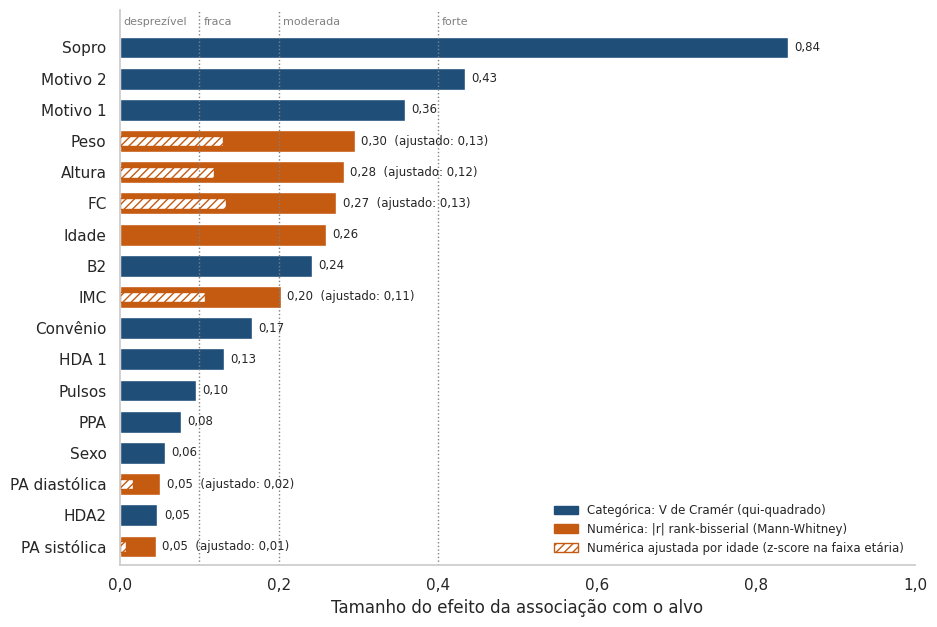

In [ ]:
ALVO = 'NORMAL X ANORMAL'
y = df[ALVO]
faixa = pd.cut(df['IDADE'], [0, 1, 3, 6, 13, 20], right=False)

def br(x, casas=2):
    """Número com vírgula decimal."""
    return f'{x:.{casas}f}'.replace('.', ',')

def v_cramer(s):
    """V de Cramér (qui-quadrado); ausentes entram como 'Não informado'."""
    tab = pd.crosstab(s.fillna('Não informado'), y)
    chi2 = chi2_contingency(tab, correction=False)[0]
    return np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))

def r_mw(valores):
    """|r| rank-bisserial a partir do U de Mann-Whitney."""
    d = pd.DataFrame({'x': valores, 'y': y}).dropna()
    a, b = d.loc[d.y == 'Anormal', 'x'], d.loc[d.y == 'Normal', 'x']
    return abs(2 * mannwhitneyu(a, b)[0] / (len(a) * len(b)) - 1)

def z(col):
    """Valor padronizado dentro da faixa etária (remove o efeito da idade)."""
    return df[col].groupby(faixa, observed=True).transform(lambda s: (s - s.mean()) / s.std())

nomes = {'SOPRO': 'Sopro', 'MOTIVO2': 'Motivo 2', 'MOTIVO1': 'Motivo 1', 'B2': 'B2',
         'Convenio': 'Convênio', 'HDA 1': 'HDA 1', 'PULSOS': 'Pulsos', 'PPA': 'PPA', 'SEXO': 'Sexo',
         'HDA2': 'HDA2', 'IDADE': 'Idade', 'Peso': 'Peso', 'Altura': 'Altura', 'IMC': 'IMC',
         'FC': 'FC', 'PA SISTOLICA': 'PA sistólica', 'PA DIASTOLICA': 'PA diastólica'}

linhas = []
for c in ['SOPRO', 'MOTIVO2', 'MOTIVO1', 'B2', 'Convenio', 'HDA 1', 'PULSOS', 'PPA', 'SEXO', 'HDA2']:
    linhas.append((nomes[c], 'Categórica', v_cramer(df[c]), np.nan))
for c in ['IDADE', 'Peso', 'Altura', 'IMC', 'FC', 'PA SISTOLICA', 'PA DIASTOLICA']:
    linhas.append((nomes[c], 'Numérica', r_mw(df[c]), np.nan if c == 'IDADE' else r_mw(z(c))))
res = pd.DataFrame(linhas, columns=['variavel', 'tipo', 'efeito', 'ajustado']).sort_values('efeito')

# ---------------------------------------------------------------- gráfico
COR = {'Categórica': '#1F4E79', 'Numérica': '#C55A11'}
fig, ax = plt.subplots(figsize=(9.5, 6.4))
ypos = np.arange(len(res))

ax.barh(ypos, res['efeito'], color=res['tipo'].map(COR), height=0.7)
ajust = res['ajustado'].notna()
ax.barh(ypos[ajust], res.loc[ajust, 'ajustado'], color='white', edgecolor='#C55A11',
        hatch='////', height=0.34)

for i, (e, a) in enumerate(zip(res['efeito'], res['ajustado'])):
    texto = br(e) + (f'  (ajustado: {br(a)})' if pd.notna(a) else '')
    ax.text(e + 0.008, i, texto, va='center', fontsize=8.5)

# faixas de força do efeito
for lim, rot in [(0.1, 'fraca'), (0.2, 'moderada'), (0.4, 'forte')]:
    ax.axvline(lim, ls=':', color='grey', lw=1)
    ax.text(lim + 0.005, len(res) - 0.35, rot, fontsize=8, color='grey', va='bottom')
ax.text(0.005, len(res) - 0.35, 'desprezível', fontsize=8, color='grey', va='bottom')

ax.set_yticks(ypos, res['variavel'])
ax.set_xlim(0, 1.0)
ax.set_ylim(-0.6, len(res) + 0.2)
ax.set_xlabel('Tamanho do efeito da associação com o alvo')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v, 1)))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COR['Categórica']),
                   plt.Rectangle((0, 0), 1, 1, color=COR['Numérica']),
                   plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='#C55A11', hatch='////')],
          labels=['Categórica: V de Cramér (qui-quadrado)',
                  'Numérica: |r| rank-bisserial (Mann-Whitney)',
                  'Numérica ajustada por idade (z-score na faixa etária)'],
          loc='lower right', fontsize=8.5, frameon=False)

fig.tight_layout()
fig.savefig('figura_bivariada_resumo.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.3 Transformações planejadas (para o relatório)
Listar com justificativa, por exemplo: remover ID, codificar categóricas, normalizar numéricas, discretizar IDADE em faixas pediátricas.

In [ ]:
print(df.columns)

Index(['ID', 'Peso', 'Altura', 'IMC', 'Atendimento', 'DN', 'IDADE', 'Convenio',
       'PULSOS', 'PA SISTOLICA', 'PA DIASTOLICA', 'PPA', 'NORMAL X ANORMAL',
       'B2', 'SOPRO', 'FC', 'HDA 1', 'HDA2', 'SEXO', 'MOTIVO1', 'MOTIVO2',
       'FC_AUSENTE'],
      dtype='object')
